# 04 — Community Intelligence: Coverage, Comparability & Historical Reliability
**Dubai Real Estate Analytics V2 · RQ07 / RQ08 / RQ09 / RQ13 / community extension of RQ03**

**Scope.** Frozen DLD recorded sales, 2010–2025 completed years; principal comparisons 2021 and 2025. P0 all eligible sales determines registered activity and nominal consideration; P1 Strict determines residential prices and sizes; P2 is required **only** for bedroom-controlled analyses. Neither price levels nor matched changes constitute repeat sales, rental yields, constant-quality housing-stock values, buyer demand, liquidity or investment returns. **All observed communities** remain in the evidence registry, including those with insufficient price support. The notebook computes new results rather than copying Notebook 02's citywide adjusted number onto local areas.

**Research gates.** Eligibility is chosen using counts/coverage/weight concentration *before* computing changes. Detailed matching can worsen selection. Community identifier continuity is observational, not independently verified geographic-boundary continuity. An unavailable result stays missing and receives `NOT ESTIMABLE`, not a zero or citywide proxy.

## 02 — Prespecified estimands and lineage
- P0 `eligible_market_activity`, dates 2010–2025: counts and gross **registered sale consideration**, not cash inflows.
- P1 Strict `eligible_residential_strict`, same dates: transaction-level nominal AED/sqm, floor area, budgets, and adjusted comparisons.
- P2 `eligible_known_segment`: bedroom-controlled sensitivity; unknown bedrooms remain unknown; `rooms_bucket=5` means **5+**.
- Matched community-group outcome: 2021 count-weighted mean of log 2025/2021 *group medians*; requires same group in both endpoints. It does **not** hold all dwelling characteristics constant.
- Raw community price-level differences are not comparable-property differences. Cross-community differences are reported only within **the same defined submarket** where independently supported; no blanket rankings.
- A 2021/2025 matched pair is distinct from annual chain links. Overlapping histories are never silently interpolated.
- Uncertainty intervals are conditional on observed groups, not on unobserved buildings, source selection or physical stock.

In [1]:
from pathlib import Path
import sys, hashlib, platform, json, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src'/'loader.py').exists() and (p/'data'/'raw'/'dld_sales_transactions.parquet').exists()),None)
if ROOT is None:raise FileNotFoundError('Run in Dubai_Real_Estate_Analytics_V2 or its notebooks/ folder, with src/ and data/raw present')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.loader import load_and_validate
from src.cleaning import clean_transactions,cohort_audit
from src.features import engineer_features
SHA='8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e'
T0,T1=2021,2025
SEED=202604
OUT=ROOT/'reports'/'tables';FIG=ROOT/'reports'/'figures';AGG=ROOT/'data'/'aggregates'
for path in (OUT,FIG,AGG):path.mkdir(parents=True,exist_ok=True)
raw,source,validation=load_and_validate(root=ROOT,expected_sha256=SHA,strict=True)
assert validation.passed and source.sha256==SHA and len(raw.columns)==20
source_manifest=pd.DataFrame([dict(source_sha256=SHA,source_rows=len(raw),source_columns=len(raw.columns),python=platform.python_version(),pandas=pd.__version__,numpy=np.__version__,seed=SEED,notebook='04_Community_Intelligence')])
display(source_manifest)
print('Source warnings:',len(validation.warnings),'critical errors:',len(validation.errors))

,source_sha256,source_rows,source_columns,python,pandas,numpy,seed,notebook
0,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,1382848,20,3.11.18,2.3.3,2.4.6,202604,04_Community_Intelligence


Source warnings: 6 critical errors: 0


In [2]:
cleaned=clean_transactions(raw)
f=engineer_features(cleaned)
assert f.index.equals(raw.index) and len(f)==len(raw)
for col in raw.columns:pd.testing.assert_series_equal(f[col],raw[col],check_names=True)
years=f.year.between(2010,2025).fillna(False)
p0=f.loc[years & f.eligible_market_activity].copy()
p1core=f.loc[years & f.eligible_residential_core].copy()
p1=f.loc[years & f.eligible_residential_strict].copy()
p2=f.loc[years & f.eligible_known_segment].copy()
assert p0.transaction_id.is_unique and p1.transaction_id.is_unique
assert set(p2.transaction_id).issubset(set(p1.transaction_id))
assert np.isfinite(p1.price_per_sqm).all() and p1.price_per_sqm.gt(0).all()
for d in (p0,p1core,p1,p2):
    d['year']=d.year.astype(int)
    d['area_key']=d.area_id.astype('string')
    d['reg']=d.reg_type_label.where(d.reg_type_label.isin(['Ready','Off-Plan']),'Unknown').fillna('Unknown')
    d['ptype']=d.property_type_label.fillna('Unknown').astype(str)
    d['known_area']=d.area_key.notna()
cohort_reconciliation=pd.DataFrame([dict(population=label,n=len(d),known_geo_n=int(d.known_area.sum()),endpoint_2021=int(d.year.eq(T0).sum()),endpoint_2025=int(d.year.eq(T1).sum())) for label,d in [('P0',p0),('P1 Core',p1core),('P1 Strict',p1),('P2',p2)]])
display(cohort_reconciliation)

,population,n,known_geo_n,endpoint_2021,endpoint_2025
0,P0,1134513,1134513,59424,214803
1,P1 Core,916748,916748,46941,182395
2,P1 Strict,901642,901642,46302,178962
3,P2,864170,864170,43740,177011


## 05 — Feasibility and publication rules frozen before outcome estimation
P1 Strict community-year medians may be described with counts but are not automatically reliable comparable-property histories. Prespecified matching thresholds: **20, 30, 50** transactions per matched group in *each* endpoint. Initial community eligibility screen: **100 P1 Strict transactions in each endpoint**, then ≥2 matched groups, ≥50% P1 Strict coverage **in both endpoints**, and effective group count ≥1.5 (a pragmatic concentration screen, not proof of representativeness). Select size-controlled `C_size_only` if it passes; otherwise broad `A_broad` if it passes; otherwise no **community-wide** adjusted estimate. Detailed B/D/E remain sensitivity, not an automatic fallback. The same gating definitions are applied to all areas and never chosen from observed returns.

Within-community price growth and between-community price levels are **different estimands**. A single matched group may support a narrowly labeled submarket estimate, not a community-wide adjusted conclusion. No universal community price index or investment ranking is promised.

## 06 — Geographic identity is an observed classification, not a boundary map
`area_id` is the grouping key. Names are display metadata only. Identical names do not authorize merging IDs; one ID with multiple names signals naming inconsistency. Missing community IDs remain outside known-community comparisons and appear in the reconciliation. First/last observed transaction does not establish a community's construction date or physical boundary change.

In [3]:
known=p0.loc[p0.known_area].copy()
areas=sorted(known.area_key.unique().tolist())
registry0=(known.groupby('area_key').agg(p0_n=('transaction_id','size'),first_year=('year','min'),last_year=('year','max'),active_years=('year','nunique'),registered_value_aed=('price_aed','sum')).reset_index())
labels=(known.dropna(subset=['area_name_en']).groupby('area_key').area_name_en.agg(lambda s:s.astype(str).value_counts().index[0] if len(s) else pd.NA).rename('area_name').reset_index())
name_conflicts=(known.dropna(subset=['area_name_en']).groupby('area_key').area_name_en.nunique().rename('name_variants').reset_index())
community_identity_registry=registry0.merge(labels,on='area_key',how='left').merge(name_conflicts,on='area_key',how='left',validate='one_to_one')
community_identity_registry['name_variants']=community_identity_registry.name_variants.fillna(0).astype(int)
reverse=(known.dropna(subset=['area_name_en']).groupby('area_name_en').area_key.nunique().reset_index(name='area_id_variants'))
community_identity_exceptions=community_identity_registry.query('name_variants>1').copy()
assert community_identity_registry.area_key.is_unique and len(community_identity_registry)==len(areas)
display(community_identity_registry[['area_key','area_name','p0_n','first_year','last_year','name_variants']].head(8))
print('Observed areas:',len(areas),'IDs with multiple labels:',len(community_identity_exceptions),'names shared across IDs:',int(reverse.area_id_variants.gt(1).sum()))

,area_key,area_name,p0_n,first_year,last_year,name_variants
0,230.0,Abu Hail,464,2010,2025,1
1,231.0,Al Mamzer,342,2010,2025,1
2,232.0,Mirdif,3509,2010,2025,1
3,233.0,Hor Al Anz,1132,2010,2025,1
4,234.0,Hor Al Anz East,90,2010,2025,1
5,235.0,Eyal Nasser,111,2010,2025,1
6,237.0,Al Sabkha,21,2010,2024,1
7,238.0,Al Dhagaya,150,2010,2025,1


Observed areas: 203 IDs with multiple labels: 0 names shared across IDs: 0


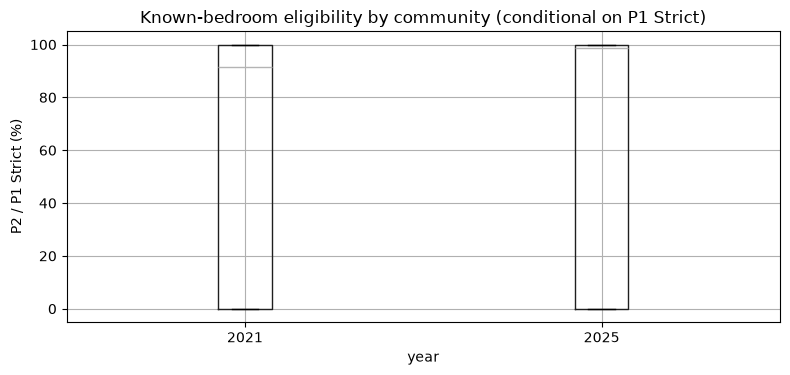

population,strict_over_p0_pct,p2_over_strict_pct
year,,
2021,37.5,91.376147
2025,50.0,98.676835


,year,room_known,n,median_area_sqm,median_psm
0,2021,False,2511,451.45,7276.471598
1,2021,True,3008,259.90,8862.232327
2,2025,False,1894,594.58,11597.261649
3,2025,True,4633,209.07,16062.413951


In [4]:
pops={'P0':p0,'P1_CORE':p1core,'P1_STRICT':p1,'P2_KNOWN_ROOMS':p2}
coverage_parts=[]
for label,frame in pops.items():
    tmp=frame.loc[frame.known_area].groupby(['area_key','year']).size().rename('n').reset_index()
    tmp['population']=label;coverage_parts.append(tmp)
community_cohort_coverage=pd.concat(coverage_parts,ignore_index=True)
wide=community_cohort_coverage.pivot_table(index=['area_key','year'],columns='population',values='n',fill_value=0,aggfunc='sum').reset_index()
for col in pops:
    if col not in wide:wide[col]=0
wide['strict_over_p0_pct']=np.where(wide.P0>0,100*wide.P1_STRICT/wide.P0,np.nan)
wide['p2_over_strict_pct']=np.where(wide.P1_STRICT>0,100*wide.P2_KNOWN_ROOMS/wide.P1_STRICT,np.nan)
assert wide[['P1_CORE','P1_STRICT','P2_KNOWN_ROOMS']].le(wide.P0,axis=0).all().all()
fig,ax=plt.subplots(figsize=(8,4))
wide.loc[wide.year.isin([T0,T1])].boxplot(column='p2_over_strict_pct',by='year',ax=ax)
plt.suptitle('');ax.set(title='Known-bedroom eligibility by community (conditional on P1 Strict)',ylabel='P2 / P1 Strict (%)')
fig.tight_layout();fig.savefig(FIG/'04_community_cohort_selection.png',dpi=145);plt.show()
display(wide.loc[wide.year.isin([T0,T1])].groupby('year')[['strict_over_p0_pct','p2_over_strict_pct']].median())
# Explicit Ready-villa selection audit; note that bedroom-known records may
# differ systematically in physical size and are NOT an unbiased subsample.
ready_villas=p1.loc[p1.ptype.eq('Villa')&p1.reg.eq('Ready')&p1.year.isin([T0,T1])].copy()
ready_villas['room_known']=pd.to_numeric(ready_villas.rooms_bucket,errors='coerce').isin([0,1,2,3,4,5])
ready_villa_selection=(ready_villas.groupby(['year','room_known']).agg(n=('transaction_id','size'),median_area_sqm=('area_sqm','median'),median_psm=('price_per_sqm','median')).reset_index())
display(ready_villa_selection)

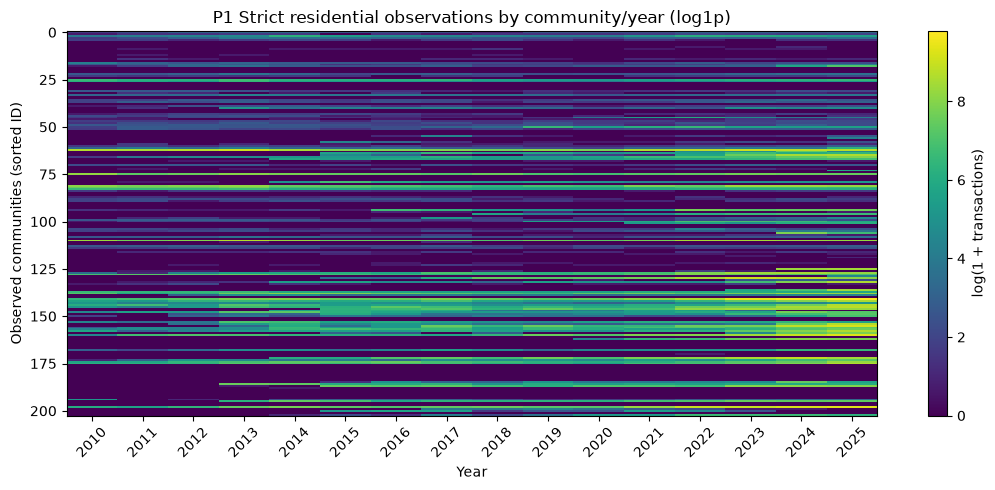

P1 endpoint basic screen passed: 46 of 203


In [5]:
community_year_counts=(p0.loc[p0.known_area].groupby(['area_key','year']).size().rename('p0_n').reset_index())
strict_year_counts=(p1.loc[p1.known_area].groupby(['area_key','year']).size().rename('p1_n').reset_index())
allgrid=pd.MultiIndex.from_product([areas,range(2010,2026)],names=['area_key','year']).to_frame(index=False)
continuity=allgrid.merge(community_year_counts,on=['area_key','year'],how='left').merge(strict_year_counts,on=['area_key','year'],how='left')
continuity[['p0_n','p1_n']]=continuity[['p0_n','p1_n']].fillna(0).astype(int)
rows=[]
for area,grp in continuity.groupby('area_key'):
    vals=grp.sort_values('year').p1_n.to_numpy()
    eligible=vals>=30
    streak=0;best=0
    for ok in eligible:
        streak=streak+1 if ok else 0;best=max(best,streak)
    endpoint=grp.set_index('year').p1_n
    rows.append(dict(area_key=area,p0_active_years=int(grp.p0_n.gt(0).sum()),strict_active_years=int(grp.p1_n.gt(0).sum()),years_strict_n30=int(eligible.sum()),max_consecutive_strict_years_n30=best,p1_2021_n=int(endpoint.loc[T0]),p1_2025_n=int(endpoint.loc[T1]),passes_basic_endpoints=bool(endpoint.loc[T0]>=100 and endpoint.loc[T1]>=100)))
community_continuity=pd.DataFrame(rows)
community_eligibility_screen=community_continuity.copy()
assert len(community_continuity)==len(areas)
heat=continuity.pivot(index='area_key',columns='year',values='p1_n').fillna(0)
fig,ax=plt.subplots(figsize=(11,5));im=ax.imshow(np.log1p(heat.to_numpy()),aspect='auto',interpolation='nearest');ax.set(title='P1 Strict residential observations by community/year (log1p)',xlabel='Year',ylabel='Observed communities (sorted ID)');ax.set_xticks(range(16));ax.set_xticklabels(range(2010,2026),rotation=45);fig.colorbar(im,ax=ax,label='log(1 + transactions)');fig.tight_layout();fig.savefig(FIG/'04_community_continuity.png',dpi=145);plt.show()
print('P1 endpoint basic screen passed:',int(community_eligibility_screen.passes_basic_endpoints.sum()),'of',len(areas))

In [6]:
community_evidence_registry=(community_identity_registry.merge(community_continuity,on='area_key',validate='one_to_one').merge(wide.loc[wide.year.eq(T0),['area_key','p2_over_strict_pct']].rename(columns={'p2_over_strict_pct':'p2_retention_2021_pct'}),on='area_key',how='left').merge(wide.loc[wide.year.eq(T1),['area_key','p2_over_strict_pct']].rename(columns={'p2_over_strict_pct':'p2_retention_2025_pct'}),on='area_key',how='left'))
community_evidence_registry['activity_profile_available']=community_evidence_registry.p0_n.gt(0)
community_evidence_registry['matched_price_candidate']=community_evidence_registry.passes_basic_endpoints
community_evidence_registry['price_status_initial']=np.where(community_evidence_registry.matched_price_candidate,'FEASIBILITY_PENDING','INSUFFICIENT_ENDPOINT_OBSERVATIONS')
assert community_evidence_registry.area_key.is_unique and set(community_evidence_registry.area_key)==set(areas)
display(community_evidence_registry.price_status_initial.value_counts().rename_axis('status').to_frame('communities'))

,communities
status,
INSUFFICIENT_ENDPOINT_OBSERVATIONS,157
FEASIBILITY_PENDING,46


## 11 — Community profiles are conditional distributions of registrations
Activity is P0 (including nonresidential/land). Residential unit price, area and budget metrics use P1 Strict. Community–year totals are *not* the value of its housing stock. Transaction mix is not dwelling stock mix. Preserve unknown geography and source flags in denominators, and do not compare the absolute AED/sqm of differently composed communities as property-quality-adjusted levels.

In [7]:
activity=(known.groupby(['area_key','year']).agg(p0_transactions=('transaction_id','size'),registered_value_aed=('price_aed','sum'),p0_mean_consideration=('price_aed','mean')).reset_index())
prices=(p1.loc[p1.known_area].groupby(['area_key','year']).agg(p1_strict_n=('transaction_id','size'),median_psm=('price_per_sqm','median'),p25_psm=('price_per_sqm',lambda s:s.quantile(.25)),p75_psm=('price_per_sqm',lambda s:s.quantile(.75)),median_price_aed=('price_aed','median'),median_area_sqm=('area_sqm','median')).reset_index())
community_yearly_profile=(allgrid.merge(activity,on=['area_key','year'],how='left').merge(prices,on=['area_key','year'],how='left').merge(community_identity_registry[['area_key','area_name']],on='area_key',how='left'))
community_yearly_profile['p0_transactions']=community_yearly_profile.p0_transactions.fillna(0).astype(int)
community_yearly_profile['registered_value_aed']=community_yearly_profile.registered_value_aed.fillna(0)
community_yearly_profile['p1_strict_n']=community_yearly_profile.p1_strict_n.fillna(0).astype(int)
assert int(community_yearly_profile.p0_transactions.sum())==len(known)
assert np.isclose(community_yearly_profile.registered_value_aed.sum(),known.price_aed.sum())
assert int(community_yearly_profile.p1_strict_n.sum())==int(p1.known_area.sum())
display(community_yearly_profile.loc[community_yearly_profile.year.eq(T1)].sort_values('p0_transactions',ascending=False).head(8))

,area_key,year,p0_transactions,registered_value_aed,p0_mean_consideration,p1_strict_n,median_psm,p25_psm,p75_psm,median_price_aed,median_area_sqm,area_name
2271,441.0,2025,18778,2.453625e+10,1.306649e+06,17735,15852.191976,13762.576316,18068.946425,1009302.0,69.12,Al Barsha South Fourth
3183,526.0,2025,13134,3.861471e+10,2.940057e+06,11499,27028.397566,22934.524270,30547.642888,1650000.0,70.83,Business Bay
2575,467.0,2025,11657,2.182386e+10,1.872168e+06,10883,15161.005604,12870.012870,17209.100336,1021786.0,75.94,Wadi Al Safa 5
2495,462.0,2025,10029,2.529779e+10,2.522464e+06,9693,17013.284951,13627.329193,20942.160814,1571888.0,91.06,Madinat Al Mataar
2335,445.0,2025,7615,1.788480e+10,2.348627e+06,6360,15338.530663,13563.382323,21872.587125,1502380.0,81.03,Jabal Ali First
2479,459.0,2025,7474,2.447660e+10,3.274899e+06,5727,16129.671855,15382.976451,17674.670506,1243000.0,76.06,Dubai Investment Park Second
1007,330.0,2025,7361,2.935765e+10,3.988270e+06,6558,28029.640707,19070.326634,37314.145226,2385741.0,99.41,Marsa Dubai
2543,465.0,2025,7051,2.193375e+10,3.110730e+06,5524,16169.321785,13431.677681,19964.209366,1034391.0,70.65,Wadi Al Safa 3


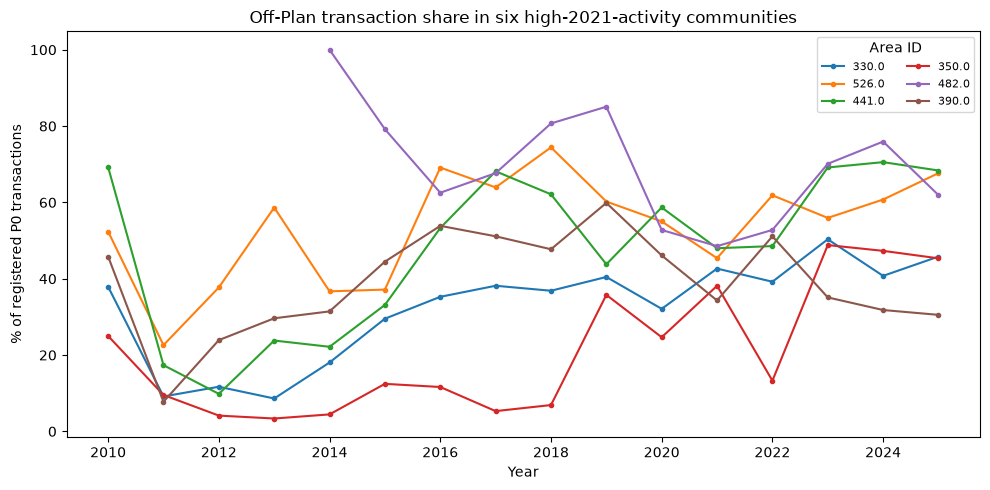

In [8]:
mx=(known.groupby(['area_key','year','ptype','reg']).agg(n=('transaction_id','size'),value_aed=('price_aed','sum')).reset_index())
den=mx.groupby(['area_key','year']).n.transform('sum')
mx['share_pct']=100*mx.n/den
community_transaction_mix=mx
mixwide=(mx.loc[mx.year.isin([T0,T1])].pivot_table(index=['area_key','ptype','reg'],columns='year',values='share_pct',fill_value=0))
for yr in [T0,T1]:
    if yr not in mixwide.columns:mixwide[yr]=0
mixwide['share_change_pp']=mixwide[T1]-mixwide[T0]
community_transaction_mix_change=mixwide.reset_index()
# High-volume community IDs selected only by 2021 activity, never by observed price changes.
selected=activity.loc[activity.year.eq(T0)].nlargest(8,'p0_transactions').area_key.tolist()
chart=(mx.loc[mx.area_key.isin(selected)].assign(type_reg=lambda d:d.ptype+' / '+d.reg).groupby(['area_key','year','type_reg']).n.sum().reset_index())
fig,ax=plt.subplots(figsize=(10,5))
for area in selected[:6]:
    d=known.loc[known.area_key.eq(area)].groupby('year').reg.apply(lambda s:s.eq('Off-Plan').mean()*100)
    ax.plot(d.index,d.values,marker='.',label=str(area))
ax.set(title='Off-Plan transaction share in six high-2021-activity communities',xlabel='Year',ylabel='% of registered P0 transactions');ax.legend(title='Area ID',ncol=2,fontsize=8);fig.tight_layout();fig.savefig(FIG/'04_community_transaction_mix.png',dpi=145);plt.show()

In [9]:
# Calendar-complete P0 activity panel: missing registration years are observed zeros,
# NOT missing periods to skip when calculating year-on-year changes.
community_activity_year_panel=(
    allgrid.merge(community_yearly_profile[['area_key','year','p0_transactions']],
                  on=['area_key','year'],how='left',validate='one_to_one')
)
community_activity_year_panel['p0_transactions']=(
    community_activity_year_panel.p0_transactions.fillna(0).astype(int)
)
comm_hist=community_activity_year_panel.sort_values(['area_key','year']).copy()
comm_hist['prior_year']=comm_hist.groupby('area_key').year.shift(1)
comm_hist['prior_n']=comm_hist.groupby('area_key').p0_transactions.shift(1)
assert comm_hist.loc[comm_hist.prior_n.notna(),'year'].sub(
    comm_hist.loc[comm_hist.prior_n.notna(),'prior_year']).eq(1).all()
comm_hist['delta_n']=comm_hist.p0_transactions-comm_hist.prior_n
# Positive/negative percentage growth is undefined when the prior-year base is zero.
comm_hist['yoy_pct']=np.where(
    comm_hist.prior_n.gt(0),100*comm_hist.delta_n/comm_hist.prior_n,np.nan)
comm_hist['newly_observed_after_zero']=comm_hist.prior_n.eq(0)&comm_hist.p0_transactions.gt(0)
comm_hist['ceased_observed_after_positive']=comm_hist.prior_n.gt(0)&comm_hist.p0_transactions.eq(0)
community_activity_history=(comm_hist.groupby('area_key').agg(
    active_years=('p0_transactions',lambda s:int(s.gt(0).sum())),
    positive_yoy_years=('delta_n',lambda s:int(s.gt(0).sum())),
    negative_yoy_years=('delta_n',lambda s:int(s.lt(0).sum())),
    median_yoy_pct=('yoy_pct','median'),
    median_annual_n=('p0_transactions','median'),
    zero_to_positive_years=('newly_observed_after_zero','sum'),
    positive_to_zero_years=('ceased_observed_after_positive','sum')
).reset_index())
activity_pair=comm_hist.loc[comm_hist.year.isin([T0,T1])].pivot(
    index='area_key',columns='year',values='p0_transactions').reindex(
    index=areas,columns=[T0,T1],fill_value=0)
community_activity_history['n_2021']=community_activity_history.area_key.map(activity_pair[T0])
community_activity_history['n_2025']=community_activity_history.area_key.map(activity_pair[T1])
community_activity_history['change_n']=(community_activity_history.n_2025-community_activity_history.n_2021)
known_delta=int(known.year.eq(T1).sum()-known.year.eq(T0).sum())
assert int(community_activity_history.change_n.sum())==known_delta
assert len(comm_hist)==len(areas)*16
assert comm_hist.loc[comm_hist.prior_n.eq(0),'yoy_pct'].isna().all()
assert comm_hist.area_key.nunique()==len(areas)
display(community_activity_history[['active_years','median_annual_n','zero_to_positive_years',
                                   'positive_to_zero_years','change_n']].describe())
print('Calendar-complete consecutive-year activity comparisons: PASS',
      '| Known-geography endpoint count change:',known_delta)


,active_years,median_annual_n,zero_to_positive_years,positive_to_zero_years,change_n
count,203.000000,203.000000,203.000000,203.000000,203.000000
mean,12.231527,225.364532,1.093596,0.891626,765.413793
std,4.959299,676.750960,1.388107,1.311819,1987.299363
min,1.000000,0.000000,0.000000,0.000000,-646.000000
25%,9.500000,1.000000,0.000000,0.000000,0.000000
50%,15.000000,8.000000,1.000000,0.000000,7.000000
75%,16.000000,45.750000,2.000000,1.000000,289.500000
max,16.000000,5642.500000,6.000000,6.000000,15094.000000


Calendar-complete consecutive-year activity comparisons: PASS | Known-geography endpoint count change: 155379


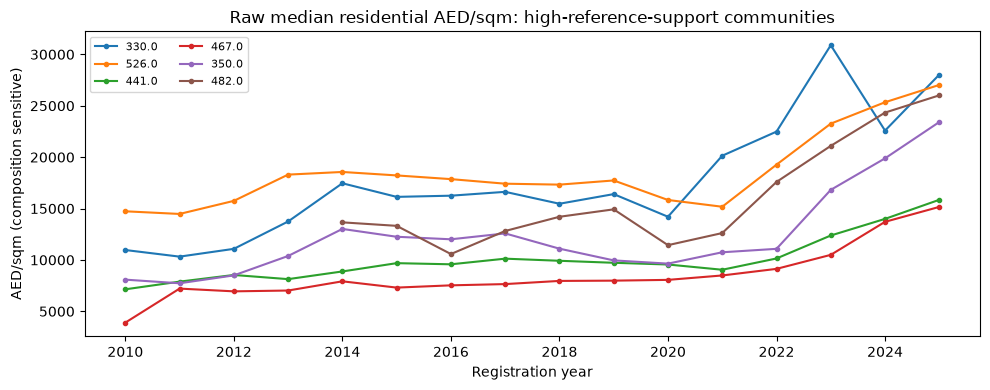

In [10]:
r=p1.loc[p1.known_area].copy()
r['log_psm']=np.log(r.price_per_sqm)
r['log_area']=np.log(r.area_sqm)
rawhist=(r.groupby(['area_key','year','ptype','reg']).agg(n=('transaction_id','size'),median_psm=('price_per_sqm','median'),median_area=('area_sqm','median'),p25_psm=('price_per_sqm',lambda s:s.quantile(.25)),p75_psm=('price_per_sqm',lambda s:s.quantile(.75))).reset_index())
community_raw_price_size_history=rawhist
# Display only a prespecified high-support sample, not best appreciating areas.
chosen=community_eligibility_screen.loc[community_eligibility_screen.passes_basic_endpoints].sort_values('p1_2021_n',ascending=False).head(6).area_key.tolist()
fig,ax=plt.subplots(figsize=(10,4))
for area in chosen:
    g=r.loc[r.area_key.eq(area)].groupby('year').price_per_sqm.agg(['size','median'])
    ax.plot(g.index,g['median'].where(g['size']>=30),marker='.',label=str(area))
ax.set(title='Raw median residential AED/sqm: high-reference-support communities',xlabel='Registration year',ylabel='AED/sqm (composition sensitive)');ax.legend(ncol=2,fontsize=8);fig.tight_layout();fig.savefig(FIG/'04_community_raw_price.png',dpi=145);plt.show()

In [11]:
# Project/building labels are raw, potentially inconsistent aliases; always show known-label coverage.
metadata=[];concentration=[]
for field in ['project_name','building_name']:
    s=known[['area_key','year',field,'transaction_id']].copy()
    s['label_known']=s[field].notna() & s[field].astype('string').str.strip().fillna('').ne('')
    g=s.groupby(['area_key','year']).label_known.agg(['size','sum']).reset_index().rename(columns={'size':'total_n','sum':'known_label_n'})
    g['known_label_pct']=np.where(g.total_n>0,100*g.known_label_n/g.total_n,np.nan);g['field']=field
    metadata.append(g)
    counts=s.loc[s.label_known].groupby(['area_key','year',field]).size().rename('n').reset_index()
    if len(counts):
        stats=(counts.groupby(['area_key','year']).agg(known_label_n=('n','sum'),largest_label_n=('n','max'),label_count=('n','size'),project_hhi=('n',lambda x:float(((x/x.sum())**2).sum()))).reset_index())
        stats['field']=field;concentration.append(stats)
community_project_metadata_quality=pd.concat(metadata,ignore_index=True)
community_project_label_concentration=pd.concat(concentration,ignore_index=True) if concentration else pd.DataFrame(columns=['area_key','year','known_label_n','largest_label_n','label_count','project_hhi','field'])
community_project_label_concentration=community_project_label_concentration.merge(community_project_metadata_quality[['area_key','year','field','known_label_pct']],on=['area_key','year','field'],how='left',validate='one_to_one')
community_project_label_concentration['interpretation_eligible']=community_project_label_concentration.known_label_pct.ge(80) & community_project_label_concentration.known_label_n.ge(100)
display(community_project_metadata_quality.groupby('field').known_label_pct.describe())
print('Known-label project/building concentration rows passing completeness gate:',int(community_project_label_concentration.interpretation_eligible.sum()))

,count,mean,std,min,25%,50%,75%,max
field,,,,,,,,
building_name,2483.0,26.093549,39.694511,0.0,0.0,0.0,66.666667,100.0
project_name,2483.0,27.419261,40.549564,0.0,0.0,0.0,71.919879,100.0


Known-label project/building concentration rows passing completeness gate: 859


## 17 — RQ07: Matched community prices, not a ranking of identical homes
Reuse *actual Notebook 02* fixed size bands: Unit coarse (0,45,65,90,125,175,250,∞), Villa coarse (0,150,225,300,400,550,750,1100,∞); its corresponding finer bands are preserved for sensitivity. A/B/C/D/E add fields exactly as in Notebook 02 (community becomes the outer grouping). All endpoint comparisons require matched observations in 2021 and 2025; **zero is not a missing estimate**. The selected method is frozen using group counts and coverage alone. Neither Citywide Notebook 02 Index A nor its direction is inherited as a local price finding.

In [12]:
COARSE={'Unit':[0,45,65,90,125,175,250,np.inf],'Villa':[0,150,225,300,400,550,750,1100,np.inf]}
FINE={'Unit':[0,35,45,55,65,80,90,110,125,150,175,225,300,np.inf],'Villa':[0,120,150,185,225,265,300,350,400,475,550,650,750,925,1100,1500,np.inf]}
for kind,spec in [('coarse',COARSE),('fine',FINE)]:
    dest=pd.Series(pd.NA,index=r.index,dtype='string')
    for ptype,bins in spec.items():
        ix=r.ptype.eq(ptype)
        dest.loc[ix]=pd.cut(r.loc[ix,'area_sqm'],bins=bins,labels=[f'{ptype}:{j:02d}' for j in range(len(bins)-1)],right=True,include_lowest=False).astype('string')
    r['size_'+kind]=dest
r['known_rooms']=pd.to_numeric(r.rooms_bucket,errors='coerce').isin([0,1,2,3,4,5])
DESIGNS={'A_broad':['ptype','reg'],'B_bedrooms':['ptype','reg','rooms_bucket'],'C_size_only':['ptype','reg','size_coarse'],'D_size_bedrooms':['ptype','reg','size_coarse','rooms_bucket'],'E_fine_bedrooms':['ptype','reg','size_fine','rooms_bucket']}
def design_eligible(frame,design):
    keys=DESIGNS[design]
    mask=frame.area_key.notna() & frame.ptype.isin(['Unit','Villa']) & frame.reg.isin(['Ready','Off-Plan']) & frame[keys].notna().all(axis=1)
    if 'rooms_bucket' in keys:mask &= frame.known_rooms
    return frame.loc[mask].copy()
community_matching_definitions=pd.DataFrame([dict(design=k,keys='area_key | '+' | '.join(v),requires_bedrooms='rooms_bucket' in v) for k,v in DESIGNS.items()])
assert r.size_coarse.notna().all()
display(community_matching_definitions)

,design,keys,requires_bedrooms
0,A_broad,area_key | ptype | reg,False
1,B_bedrooms,area_key | ptype | reg | rooms_bucket,True
2,C_size_only,area_key | ptype | reg | size_coarse,False
3,D_size_bedrooms,area_key | ptype | reg | size_coarse | rooms_b...,True
4,E_fine_bedrooms,area_key | ptype | reg | size_fine | rooms_bucket,True


,design,all_communities,areas_with_match,share_of_all_communities_pct,median_2021_coverage_if_matched,median_2025_coverage_if_matched
0,A_broad,203.0,53.0,26.108374,100.000000,99.560547
1,B_bedrooms,203.0,45.0,22.167488,82.934132,66.828479
2,C_size_only,203.0,45.0,22.167488,80.971660,51.194969
3,D_size_bedrooms,203.0,43.0,21.182266,64.423077,39.601140
4,E_fine_bedrooms,203.0,41.0,20.197044,55.778894,28.089888


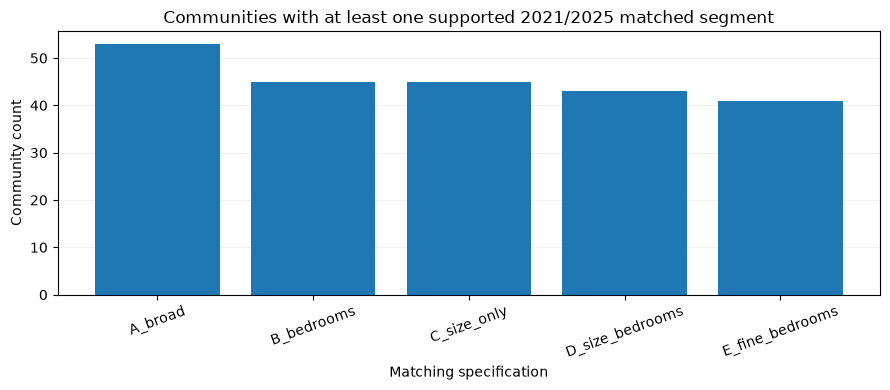

CELL 19 — MATCHING FEASIBILITY VERIFICATION
Observed communities: 203
Matching designs: 5
Support thresholds: [20, 30, 50]
Feasibility rows: 3045
2021: zero-parent rows=1530; maximum defined coverage=100.00%
2025: zero-parent rows=1350; maximum defined coverage=100.00%
Matched counts <= parent counts: PASS
Coverage arithmetic: PASS
Undefined coverage handled correctly: PASS
Research population preserved: PASS


In [13]:
# ============================================================
# CELL 19 — Community Matched-Support Feasibility
# ============================================================
# Matching eligibility is determined WITHOUT examining prices.
#
# Important:
# - Every observed community must remain in the registry.
# - Matched counts must never exceed P1 Strict parent counts.
# - Zero parent counts imply undefined coverage (NaN).
# - Missing coverage is not a mathematical failure.
# - No missing community is assigned fabricated support.
# ============================================================

END = r.loc[r.year.isin([T0, T1])].copy()

THRESHOLDS = [20, 30, 50]

# 1. Establish the canonical P1 Strict endpoint denominators.
endpoint_parent = (
    END.groupby(["area_key", "year"], observed=True)
    .size()
    .unstack("year", fill_value=0)
    .reindex(
        index=areas,
        columns=[T0, T1],
        fill_value=0
    )
    .astype(int)
)

# Parent population integrity.
assert END.transaction_id.is_unique, (
    "Duplicate P1 Strict transaction IDs in endpoint population."
)

assert (
    endpoint_parent.to_numpy().sum() == len(END)
), "Endpoint population reconciliation failed."

all_support = []

# 2. Evaluate the matching specifications separately.
for design, keys in DESIGNS.items():

    frame = design_eligible(END, design)

    # A design's feature-eligible cohort must be a
    # subset of P1 Strict.
    assert frame.transaction_id.is_unique, (
        f"{design}: Duplicate eligible transaction IDs."
    )

    assert len(frame) <= len(END), (
        f"{design}: Eligible population exceeds P1 Strict."
    )

    # Count transactions in each group and endpoint year.
    grouped = (
        frame.groupby(
            ["area_key"] + keys + ["year"],
            observed=True
        )
        .size()
        .unstack("year", fill_value=0)
        .reindex(
            columns=[T0, T1],
            fill_value=0
        )
    )

    # Check the complete group partition before matching.
    assert int(grouped.to_numpy().sum()) <= len(frame), (
        f"{design}: Grouped counts exceed eligible transactions."
    )

    for threshold in THRESHOLDS:

        # Require adequate support in BOTH endpoint years.
        if grouped.empty:
            matched = pd.DataFrame(
                columns=["area_key", T0, T1]
            )
        else:
            supported = (
                grouped[T0].ge(threshold)
                & grouped[T1].ge(threshold)
            )

            matched = (
                grouped.loc[supported]
                .reset_index()
            )

        for area in areas:

            chunk = matched.loc[
                matched["area_key"].eq(area)
            ]

            matched_2021 = (
                int(chunk[T0].sum())
                if len(chunk) else 0
            )

            matched_2025 = (
                int(chunk[T1].sum())
                if len(chunk) else 0
            )

            parent_2021 = int(
                endpoint_parent.loc[area, T0]
            )

            parent_2025 = int(
                endpoint_parent.loc[area, T1]
            )

            # Fundamental subset relationships.
            if matched_2021 > parent_2021:
                raise AssertionError(
                    f"{design}, area={area}, "
                    f"threshold={threshold}: "
                    f"matched 2021 count "
                    f"{matched_2021} exceeds "
                    f"P1 Strict count {parent_2021}."
                )

            if matched_2025 > parent_2025:
                raise AssertionError(
                    f"{design}, area={area}, "
                    f"threshold={threshold}: "
                    f"matched 2025 count "
                    f"{matched_2025} exceeds "
                    f"P1 Strict count {parent_2025}."
                )

            # Undefined denominators remain NaN.
            coverage_2021 = (
                100.0 * matched_2021 / parent_2021
                if parent_2021 > 0
                else np.nan
            )

            coverage_2025 = (
                100.0 * matched_2025 / parent_2025
                if parent_2025 > 0
                else np.nan
            )

            # Fixed-2021 transaction-count weights.
            if matched_2021 > 0:

                weights = (
                    chunk[T0].astype(float)
                    / matched_2021
                )

                assert np.isclose(
                    weights.sum(), 1.0,
                    atol=1e-12
                ), (
                    f"{design}, area={area}: "
                    "Reference weights do not sum to one."
                )

                effective_groups = float(
                    1.0 / np.square(weights).sum()
                )

                largest_weight_pct = float(
                    100.0 * weights.max()
                )

            else:
                effective_groups = np.nan
                largest_weight_pct = np.nan

            all_support.append({
                "area_key": area,
                "design": design,
                "min_cell_n": threshold,
                "matched_groups": int(len(chunk)),
                "matched_2021_n": matched_2021,
                "matched_2025_n": matched_2025,
                "p1_2021_n": parent_2021,
                "p1_2025_n": parent_2025,
                "coverage_2021_pct": coverage_2021,
                "coverage_2025_pct": coverage_2025,
                "effective_groups": effective_groups,
                "largest_weight_pct": largest_weight_pct
            })


# 3. Construct the complete community/design/threshold registry.
community_matching_feasibility = pd.DataFrame(
    all_support
)

fullidx = (
    pd.MultiIndex.from_product(
        [areas, list(DESIGNS), THRESHOLDS],
        names=[
            "area_key",
            "design",
            "min_cell_n"
        ]
    )
    .to_frame(index=False)
)

community_matching_feasibility = fullidx.merge(
    community_matching_feasibility,
    on=["area_key", "design", "min_cell_n"],
    how="left",
    validate="one_to_one"
)

# Every community must have all candidate screening rows.
expected_rows = (
    len(areas)
    * len(DESIGNS)
    * len(THRESHOLDS)
)

assert len(community_matching_feasibility) == expected_rows

# Counts are zero for genuinely unsupported groups.
for field in [
    "matched_groups",
    "matched_2021_n",
    "matched_2025_n"
]:
    community_matching_feasibility[field] = (
        community_matching_feasibility[field]
        .fillna(0)
        .astype(int)
    )

# Ensure parent denominators are present for every area.
for year in [T0, T1]:

    parent_col = f"p1_{year}_n"

    community_matching_feasibility[parent_col] = (
        community_matching_feasibility[parent_col]
        .fillna(
            community_matching_feasibility[
                "area_key"
            ].map(endpoint_parent[year])
        )
        .astype(int)
    )

# 4. Correct coverage validation.
# NaN is acceptable ONLY where the parent is zero.

for year in [T0, T1]:

    parent_col = f"p1_{year}_n"
    matched_col = f"matched_{year}_n"
    coverage_col = f"coverage_{year}_pct"

    parent = community_matching_feasibility[parent_col]
    matched_n = community_matching_feasibility[matched_col]
    coverage = community_matching_feasibility[coverage_col]

    # Matched transactions must belong to the parent.
    assert matched_n.le(parent).all(), (
        f"{year}: Matched counts exceed P1 Strict."
    )

    # A zero parent must have zero matched transactions.
    assert matched_n.loc[parent.eq(0)].eq(0).all(), (
        f"{year}: Zero-parent communities have matched records."
    )

    # Coverage is undefined when denominator is zero.
    assert coverage.loc[parent.eq(0)].isna().all(), (
        f"{year}: Zero-denominator coverage must be NaN."
    )

    # Positive denominators must have finite coverage.
    valid = parent.gt(0)

    assert coverage.loc[valid].notna().all(), (
        f"{year}: Missing coverage with positive denominator."
    )

    assert np.isfinite(
        coverage.loc[valid].to_numpy(dtype=float)
    ).all(), (
        f"{year}: Non-finite coverage."
    )

    assert coverage.loc[valid].between(
        0, 100.00001
    ).all(), (
        f"{year}: Coverage outside 0–100%."
    )

    # Independently recompute all defined percentages.
    expected_coverage = (
        100.0
        * matched_n.loc[valid].to_numpy(dtype=float)
        / parent.loc[valid].to_numpy(dtype=float)
    )

    assert np.allclose(
        coverage.loc[valid].to_numpy(dtype=float),
        expected_coverage,
        rtol=1e-12,
        atol=1e-10
    ), (
        f"{year}: Coverage arithmetic mismatch."
    )


# 5. Separate all-community participation from coverage among supported areas.
primary_support=community_matching_feasibility.query('min_cell_n == 30').copy()
primary_support['has_match']=primary_support.matched_groups.gt(0)
qual=(primary_support.groupby('design',observed=True).apply(
    lambda d:pd.Series({
        'all_communities':len(d),
        'areas_with_match':int(d.has_match.sum()),
        'share_of_all_communities_pct':100*d.has_match.mean(),
        'median_2021_coverage_if_matched':d.loc[d.has_match,'coverage_2021_pct'].median(),
        'median_2025_coverage_if_matched':d.loc[d.has_match,'coverage_2025_pct'].median(),
    }),include_groups=False).reset_index())
assert qual.all_communities.eq(len(areas)).all()
assert qual.areas_with_match.between(0,len(areas)).all()
display(qual)

# 6. Visualize the feasible community counts.
fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    qual["design"],
    qual["areas_with_match"]
)

ax.set(
    title=(
        "Communities with at least one supported "
        "2021/2025 matched segment"
    ),
    xlabel="Matching specification",
    ylabel="Community count"
)

ax.tick_params(
    axis="x", rotation=20
)

ax.grid(
    axis="y", alpha=0.2
)

ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    FIG / "04_community_matched_support.png",
    dpi=145,
    bbox_inches="tight"
)

plt.show()

# 7. Diagnostic summary.
print("=" * 65)
print("CELL 19 — MATCHING FEASIBILITY VERIFICATION")
print("=" * 65)

print("Observed communities:", len(areas))
print("Matching designs:", len(DESIGNS))
print("Support thresholds:", THRESHOLDS)
print("Feasibility rows:", len(community_matching_feasibility))

for year in [T0, T1]:

    parent_col = f"p1_{year}_n"
    coverage_col = f"coverage_{year}_pct"

    zero_parent_rows = int(
        community_matching_feasibility[
            parent_col
        ].eq(0).sum()
    )

    max_coverage = (
        community_matching_feasibility[
            coverage_col
        ].max()
    )

    print(
        f"{year}: zero-parent rows={zero_parent_rows}; "
        f"maximum defined coverage={max_coverage:.2f}%"
    )

print("Matched counts <= parent counts: PASS")
print("Coverage arithmetic: PASS")
print("Undefined coverage handled correctly: PASS")
print("Research population preserved: PASS")
print("=" * 65)


In [14]:
MIN_ENDPOINT=100;MIN_CELLS=2;MIN_COVERAGE=50.;MIN_EFF=1.5
f30=community_matching_feasibility.query('min_cell_n==30').copy()
f30['passes_community_gate']=(f30.p1_2021_n.ge(MIN_ENDPOINT)&f30.p1_2025_n.ge(MIN_ENDPOINT)&f30.matched_groups.ge(MIN_CELLS)&f30.coverage_2021_pct.ge(MIN_COVERAGE)&f30.coverage_2025_pct.ge(MIN_COVERAGE)&f30.effective_groups.ge(MIN_EFF))
choice=[]
for area in areas:
    view=f30.loc[f30.area_key.eq(area)].set_index('design')
    if bool(view.loc['C_size_only','passes_community_gate']):design='C_size_only'
    elif bool(view.loc['A_broad','passes_community_gate']):design='A_broad'
    else:design=None
    choice.append(dict(area_key=area,selected_design=design if design else 'NONE',matched_price_eligible=bool(design),selection_reason='size_controlled_support' if design=='C_size_only' else 'broad_support_only' if design else 'insufficient_endpoints_or_matched_support'))
community_matching_decisions=pd.DataFrame(choice)
assert len(community_matching_decisions)==len(areas) and community_matching_decisions.area_key.is_unique
display(community_matching_decisions.selected_design.value_counts().rename_axis('selection').to_frame('communities'))

,communities
selection,
NONE,169
C_size_only,25
A_broad,9


Community-wide supported endpoint estimates: 34


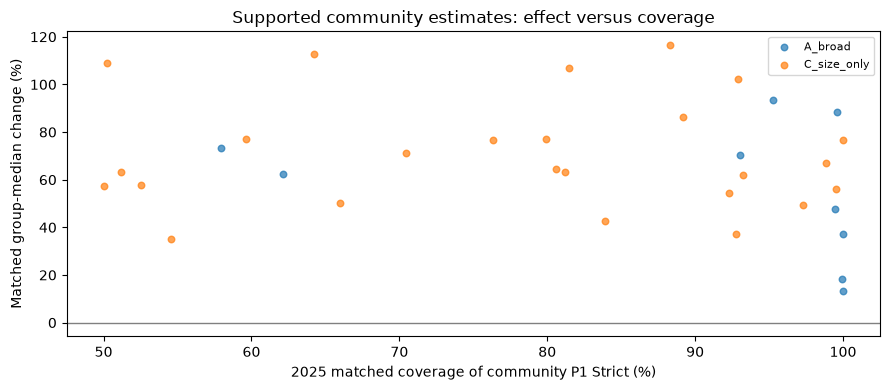

In [15]:
# Vectorized group medians once for each design, reused by endpoint and annual comparisons.
STATS={}
for design,keys in DESIGNS.items():
    frame=design_eligible(r,design)
    STATS[design]=(frame.groupby(['area_key']+keys+['year'],observed=True).agg(n=('transaction_id','size'),median_psm=('price_per_sqm','median'),mean_log_psm=('log_psm','mean')).reset_index())

def matched_pair(stats,design,base,end,min_n=30):
    keys=['area_key']+DESIGNS[design]
    base_stat=stats.loc[stats.year.eq(base),keys+['n','median_psm']].rename(columns={'n':'n_base','median_psm':'med_base'})
    end_stat=stats.loc[stats.year.eq(end),keys+['n','median_psm']].rename(columns={'n':'n_end','median_psm':'med_end'})
    hit=base_stat.merge(end_stat,on=keys,how='inner',validate='one_to_one')
    hit=hit.loc[hit.n_base.ge(min_n)&hit.n_end.ge(min_n)&hit.med_base.gt(0)&hit.med_end.gt(0)].copy()
    if hit.empty:return pd.DataFrame(),pd.DataFrame()
    hit['log_change']=np.log(hit.med_end/hit.med_base)
    hit['weight']=hit.n_base/hit.groupby('area_key').n_base.transform('sum')
    hit['weighted_change']=hit.weight*hit.log_change
    summary=(hit.groupby('area_key').agg(matched_groups=('weight','size'),matched_base_n=('n_base','sum'),matched_end_n=('n_end','sum'),log_change=('weighted_change','sum'),weight_sq=('weight',lambda x:float((x*x).sum())),top_weight=('weight','max')).reset_index())
    summary['change_pct']=100*np.expm1(summary.log_change)
    summary['effective_groups']=1/summary.weight_sq
    summary['base_year']=base;summary['end_year']=end;summary['design']=design;summary['min_cell_n']=min_n
    return summary,hit

pairs=[]
for design in DESIGNS:
    summary,_=matched_pair(STATS[design],design,T0,T1,30)
    if len(summary):pairs.append(summary)
community_price_growth_candidates=pd.concat(pairs,ignore_index=True) if pairs else pd.DataFrame(columns=['area_key','design','change_pct','matched_groups','matched_base_n','matched_end_n','log_change','effective_groups'])
community_price_growth_endpoint=(community_matching_decisions.query('matched_price_eligible').merge(community_price_growth_candidates,on=['area_key','design'],how='left') if False else community_matching_decisions.query('matched_price_eligible').rename(columns={'selected_design':'design'}).merge(community_price_growth_candidates,on=['area_key','design'],how='left',validate='one_to_one'))
community_price_growth_endpoint=community_price_growth_endpoint.merge(f30[['area_key','design','coverage_2021_pct','coverage_2025_pct','p1_2021_n','p1_2025_n','matched_groups']].rename(columns={'matched_groups':'feasibility_groups'}),on=['area_key','design'],how='left',validate='one_to_one')
assert not community_price_growth_endpoint.change_pct.isna().any()
assert np.allclose(community_price_growth_endpoint.matched_groups,community_price_growth_endpoint.feasibility_groups)
print('Community-wide supported endpoint estimates:',len(community_price_growth_endpoint))
fig,ax=plt.subplots(figsize=(9,4))
for name,grp in community_price_growth_endpoint.groupby('design'):
    ax.scatter(grp.coverage_2025_pct,grp.change_pct,label=name,s=22,alpha=.7)
ax.axhline(0,color='gray',lw=1);ax.set(xlabel='2025 matched coverage of community P1 Strict (%)',ylabel='Matched group-median change (%)',title='Supported community estimates: effect versus coverage');ax.legend(fontsize=8);fig.tight_layout();fig.savefig(FIG/'04_price_change_vs_coverage.png',dpi=145);plt.show()

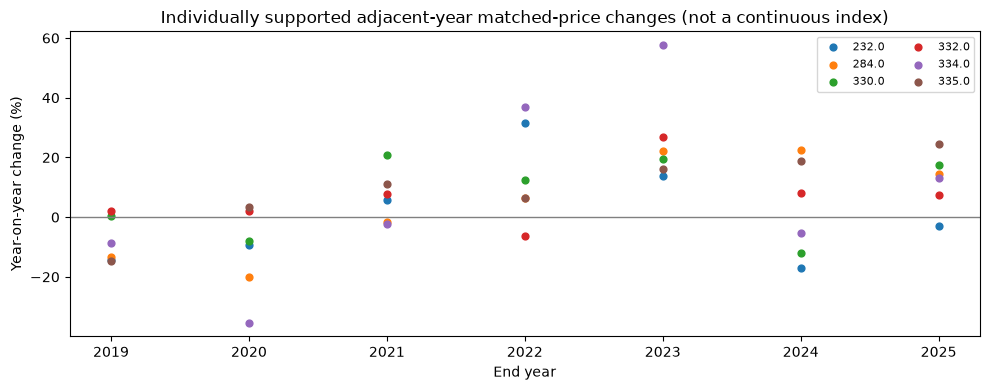

In [16]:
# Historical adjacent-year links are estimated per area/design and never imputed.
links=[]
for design in ['A_broad','C_size_only']:
    stats=STATS[design]
    for yr in range(2019,2026):
        summary,_=matched_pair(stats,design,yr-1,yr,20)
        if len(summary):links.append(summary)
community_price_history_supported=pd.concat(links,ignore_index=True) if links else pd.DataFrame(columns=['area_key','base_year','end_year','design','matched_groups','log_change'])
community_price_history_coverage=community_price_history_supported[['area_key','base_year','end_year','design','matched_groups','matched_base_n','matched_end_n','effective_groups']].copy() if len(community_price_history_supported) else pd.DataFrame()
# Continuous support requires matching each adjacent pair AND a predeclared minimum number of groups.
if len(community_price_history_supported):
    community_price_history_supported['eligible_link']=community_price_history_supported.matched_groups.ge(2)&community_price_history_supported.effective_groups.ge(1.5)
else:community_price_history_supported['eligible_link']=pd.Series(dtype=bool)
# Show only top-reference-support communities with actual supported links, not fastest grower selection.
selected=community_matching_decisions.query('matched_price_eligible').area_key.head(6).tolist()
fig,ax=plt.subplots(figsize=(10,4))
for area in selected:
    d=community_price_history_supported.loc[(community_price_history_supported.area_key.eq(area))&(community_price_history_supported.design.eq('A_broad'))].sort_values('end_year')
    if len(d):ax.scatter(d.end_year,d.change_pct,label=str(area),s=24)
ax.axhline(0,color='gray',lw=1);ax.set(title='Individually supported adjacent-year matched-price changes (not a continuous index)',xlabel='End year',ylabel='Year-on-year change (%)');ax.legend(fontsize=8,ncol=2);fig.tight_layout();fig.savefig(FIG/'04_community_price_histories.png',dpi=145);plt.show()

In [17]:
# Persistence is only evaluated over a contiguous run of eligible adjacent-year links.
rows=[]
for (area,design),d in community_price_history_supported.groupby(['area_key','design']):
    d=d.sort_values('end_year')
    eligible=d.loc[d.eligible_link].copy()
    run=0;best=0;prev=None
    for _,rec in eligible.iterrows():
        if prev is None or rec.end_year!=prev+1:run=0
        run=run+1 if rec.log_change>0 else 0
        best=max(best,run);prev=rec.end_year
    rows.append(dict(area_key=area,design=design,supported_links=len(eligible),positive_links=int(eligible.log_change.gt(0).sum()),negative_links=int(eligible.log_change.lt(0).sum()),max_continuous_positive_links=best,median_link_log_change=eligible.log_change.median() if len(eligible) else np.nan))
community_growth_persistence=pd.DataFrame(rows) if rows else pd.DataFrame(columns=['area_key','design','supported_links','positive_links','negative_links','max_continuous_positive_links','median_link_log_change'])
assert (community_growth_persistence.max_continuous_positive_links<=community_growth_persistence.supported_links).all()
display(community_growth_persistence.supported_links.value_counts().sort_index().to_frame('community_designs'))

,community_designs
supported_links,
0,34
1,12
2,10
3,11
4,8
5,9
6,13
7,41


In [18]:
community_growth_validated=community_evidence_registry[['area_key','area_name','p1_2021_n','p1_2025_n']].merge(community_matching_decisions,on='area_key',validate='one_to_one').merge(community_price_growth_endpoint[['area_key','change_pct','coverage_2021_pct','coverage_2025_pct','matched_groups','effective_groups']],on='area_key',how='left',validate='one_to_one')
community_growth_validated['decision']=np.where(community_growth_validated.matched_price_eligible,'QUALIFIED','NOT ESTIMABLE')
community_growth_validated['restriction']=np.where(community_growth_validated.matched_price_eligible,'Matched observed groups only; within-cell quality and differing community mixes remain unadjusted','Insufficient predeclared community-wide endpoint matching support')
community_growth_ineligible=community_growth_validated.loc[~community_growth_validated.matched_price_eligible].copy()
assert community_growth_validated.area_key.is_unique and len(community_growth_validated)==len(areas)
assert community_growth_ineligible.change_pct.isna().all()
display(community_growth_validated.decision.value_counts())

decision
NOT ESTIMABLE    169
QUALIFIED         34
Name: count, dtype: int64

## 25 — RQ08: Between-community prices require identical submarket definitions
Within-community matched growth does **not** standardize two different communities. For cross-community level evidence, select a single physical submarket and fixed size interval *using 2021+2025 observation support only*, then compare its 2021/2025 transaction medians among the same eligible area IDs. This is deliberately narrower than a universal standardized-price level. Pairwise comparisons outside that fixed common submarket are `NOT ESTIMABLE`. Different building quality and micro-location remain uncontrolled; a higher price is not undervaluation or investment superiority.

In [19]:
# Select a comparable Unit/Ready or Unit/Off-Plan coarse size stratum by maximum
# BOTH-endpoint eligible area count, tie-broken by canonical stratum name.
sub=r.loc[r.ptype.eq('Unit')&r.reg.isin(['Ready','Off-Plan'])&r.size_coarse.notna()&r.year.isin([T0,T1])]
subcount=sub.groupby(['reg','size_coarse','area_key','year'],observed=True).size().unstack('year',fill_value=0).reindex(columns=[T0,T1],fill_value=0).reset_index()
subcount['supported']=subcount[T0].ge(30)&subcount[T1].ge(30)
screen=subcount.groupby(['reg','size_coarse'],observed=True).supported.sum().reset_index(name='eligible_communities').sort_values(['eligible_communities','reg','size_coarse'],ascending=[False,True,True])
SELECTED_SUBMARKET=tuple(screen.iloc[0][['reg','size_coarse']]) if len(screen) and screen.eligible_communities.max()>=3 else None
community_cross_area_overlap=subcount
print('Fixed identical observable submarket:',SELECTED_SUBMARKET or 'NOT ESTIMABLE')
display(screen.head(8))

Fixed identical observable submarket: ('Ready', 'Unit:02')


,reg,size_coarse,eligible_communities
9,Ready,Unit:02,26
10,Ready,Unit:03,23
11,Ready,Unit:04,23
2,Off-Plan,Unit:02,18
3,Off-Plan,Unit:03,17
7,Ready,Unit:00,16
8,Ready,Unit:01,16
4,Off-Plan,Unit:04,13


In [20]:
community_price_level_comparisons=pd.DataFrame(columns=['area_key','year','n','median_psm','submarket_reg','size_band'])
if SELECTED_SUBMARKET is not None:
    rg,band=SELECTED_SUBMARKET
    allowed=set(subcount.loc[subcount.reg.eq(rg)&subcount.size_coarse.eq(band)&subcount.supported,'area_key'])
    chosen=sub.loc[sub.reg.eq(rg)&sub.size_coarse.eq(band)&sub.area_key.isin(allowed)]
    community_price_level_comparisons=(chosen.groupby(['area_key','year']).agg(n=('transaction_id','size'),median_psm=('price_per_sqm','median'),mean_log_psm=('log_psm','mean')).reset_index())
    community_price_level_comparisons['submarket_reg']=rg;community_price_level_comparisons['size_band']=band
    # The fixed 2021/2025 comparison universe is selected on support only.
    assert community_price_level_comparisons.loc[community_price_level_comparisons.year.isin([T0,T1])].groupby('area_key').year.nunique().eq(2).all()
print('Eligible communities in fixed common submarket:',community_price_level_comparisons.area_key.nunique())

Eligible communities in fixed common submarket: 26


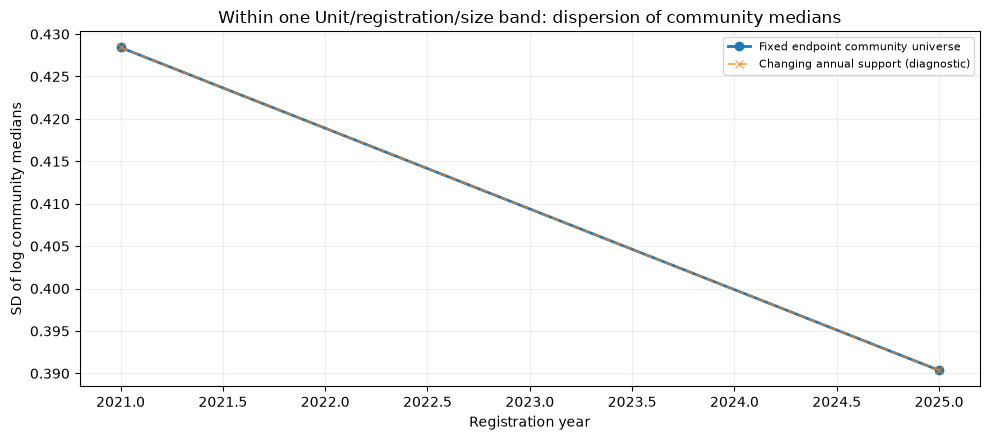

Fixed endpoint submarket: ('Ready', 'Unit:02') | endpoint common-community universe: 26


In [21]:
# Two DISTINCT dispersion estimands:
# (a) the identical endpoint-supported community universe, fixed at both T0 and T1;
# (b) an explicitly changing, year-specific supported universe (descriptive only).
cols=['year','eligible_communities','log_p90_p10','sd_log_medians','mean_log_medians',
      'universe','submarket_reg','size_band']
community_dispersion_yearly=pd.DataFrame(columns=cols)
community_dispersion_sensitivity=pd.DataFrame(columns=['year','weighting','sd_log_level','eligible_communities','universe'])
community_dispersion_changing_universe=pd.DataFrame(columns=cols)
FIXED_DISPERSION_AREAS=set()
if len(community_price_level_comparisons):
    g=community_price_level_comparisons.copy()
    endpoint=g.loc[g.year.isin([T0,T1])&g.n.ge(30)]
    support=endpoint.groupby('area_key').year.nunique()
    FIXED_DISPERSION_AREAS=set(support[support.eq(2)].index)
    assert len(FIXED_DISPERSION_AREAS)==community_price_level_comparisons.area_key.nunique()
    main=[];alternate=[];sensitivity=[]
    for year,frame in g.groupby('year'):
        for name,condition,target in [
            ('fixed_endpoint_universe',frame.area_key.isin(FIXED_DISPERSION_AREAS)&frame.n.ge(30),main),
            ('changing_annual_universe',frame.n.ge(30),alternate),
        ]:
            d=frame.loc[condition].copy()
            # A truly fixed-universe annual series requires EVERY endpoint
            # community to have sufficient observations in that year.
            # Otherwise skip this fixed-universe annual point; never plot
            # a changing subset under a fixed-universe label.
            if name=='fixed_endpoint_universe' and len(d)!=len(FIXED_DISPERSION_AREAS):
                continue
            if len(d)<3:continue
            x=np.log(d.median_psm.to_numpy(dtype=float))
            target.append(dict(year=int(year),eligible_communities=len(d),
                log_p90_p10=float(np.quantile(x,.9)-np.quantile(x,.1)),
                sd_log_medians=float(x.std(ddof=1)),mean_log_medians=float(x.mean()),
                universe=name,submarket_reg=SELECTED_SUBMARKET[0],size_band=SELECTED_SUBMARKET[1]))
            if name=='fixed_endpoint_universe':
                w=d.n.to_numpy(dtype=float);weighted_mean=np.average(x,weights=w)
                sensitivity += [
                    dict(year=int(year),weighting='equal_community',sd_log_level=float(x.std(ddof=1)),eligible_communities=len(d),universe=name),
                    dict(year=int(year),weighting='transaction_weighted',sd_log_level=float(np.sqrt(np.average((x-weighted_mean)**2,weights=w))),eligible_communities=len(d),universe=name)
                ]
    community_dispersion_yearly=pd.DataFrame(main,columns=cols)
    community_dispersion_changing_universe=pd.DataFrame(alternate,columns=cols)
    community_dispersion_sensitivity=pd.DataFrame(sensitivity)
    d=community_dispersion_yearly.set_index('year')
    if T0 in d.index and T1 in d.index:
        assert d.loc[T0,'eligible_communities']==d.loc[T1,'eligible_communities']==len(FIXED_DISPERSION_AREAS)
        assert len(FIXED_DISPERSION_AREAS)>=3
fig,ax=plt.subplots(figsize=(10,4.5))
if len(community_dispersion_yearly):
    ax.plot(community_dispersion_yearly.year,community_dispersion_yearly.sd_log_medians,
            marker='o',linewidth=2,label='Fixed endpoint community universe')
if len(community_dispersion_changing_universe):
    d=community_dispersion_changing_universe
    ax.plot(d.year,d.sd_log_medians,marker='x',linestyle='--',alpha=.65,
            label='Changing annual support (diagnostic)')
ax.set(title='Within one Unit/registration/size band: dispersion of community medians',
       xlabel='Registration year',ylabel='SD of log community medians')
ax.grid(alpha=.2);ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(FIG/'04_community_price_dispersion.png',dpi=155,bbox_inches='tight');plt.show()
print('Fixed endpoint submarket:',SELECTED_SUBMARKET,
      '| endpoint common-community universe:',len(FIXED_DISPERSION_AREAS))


In [22]:
# Do not interpret a change in the annual eligible community set as convergence.
endpoint_dispersion=community_dispersion_yearly.loc[
    community_dispersion_yearly.year.isin([T0,T1])].sort_values('year')
comparable=(SELECTED_SUBMARKET is not None and len(endpoint_dispersion)==2
            and endpoint_dispersion.eligible_communities.eq(len(FIXED_DISPERSION_AREAS)).all()
            and len(FIXED_DISPERSION_AREAS)>=3)
change_sd=(float(endpoint_dispersion.iloc[-1].sd_log_medians-
                 endpoint_dispersion.iloc[0].sd_log_medians) if comparable else np.nan)
community_convergence_decisions=pd.DataFrame([dict(
    research_question='RQ08',decision='QUALIFIED' if comparable else 'INCONCLUSIVE',
    eligible_communities=len(FIXED_DISPERSION_AREAS),submarket=str(SELECTED_SUBMARKET),
    sd_log_medians_change_2021_2025=change_sd,
    direction=('lower observed dispersion' if change_sd<0 else
               'higher observed dispersion' if change_sd>0 else 'unchanged observed dispersion') if comparable else 'not estimable',
    restriction='Observed median AED/sqm within one fixed Unit/registration/size stratum and identical 2021/2025 community IDs only; no adjustment for buildings or dwelling quality; annual missing support is not imputed.'
)])
display(community_convergence_decisions)


,research_question,decision,eligible_communities,submarket,sd_log_medians_change_2021_2025,direction,restriction
0,RQ08,QUALIFIED,26,"('Ready', 'Unit:02')",-0.038064,lower observed dispersion,Observed median AED/sqm within one fixed Unit/...


## 30 — RQ13: Observed spread, estimator uncertainty and historical volatility are different
Cross-sectional annual dispersion reflects heterogeneous recorded sales, not an annual investment-return variance. Historical standard deviations use only supported consecutive adjacent-year **log matched-price changes** and require four or more valid consecutive links. Community histories with gaps do not acquire interpolated links or drawdowns. Bootstrap intervals are conditional on the matched observed group set; they cannot identify unobserved dwelling characteristics or fix systematic selection.

**Revision:** Stability decisions use one prespecified community/design history per community, with longest consecutive supported run. Year-specific matched strata may change, so the reported dispersion is not the volatility of a fixed-quality investment. Only conditional transaction-level bootstrap volatility intervals are calculated; selection and building-quality uncertainty remains unidentified.


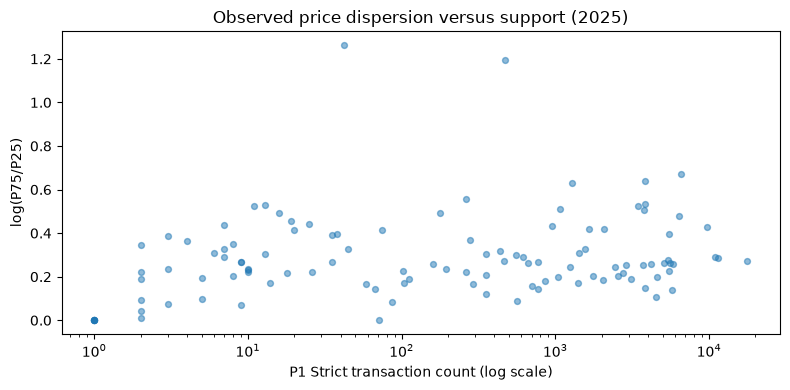

In [23]:
community_within_year_price_dispersion=(r.groupby(['area_key','year']).agg(n=('transaction_id','size'),p25_psm=('price_per_sqm',lambda s:s.quantile(.25)),p50_psm=('price_per_sqm','median'),p75_psm=('price_per_sqm',lambda s:s.quantile(.75))).reset_index())
community_within_year_price_dispersion['log_iqr']=np.log(community_within_year_price_dispersion.p75_psm/community_within_year_price_dispersion.p25_psm)
community_within_year_price_dispersion['eligible_n30']=community_within_year_price_dispersion.n.ge(30)
fig,ax=plt.subplots(figsize=(8,4));view=community_within_year_price_dispersion.loc[community_within_year_price_dispersion.year.eq(T1)]
ax.scatter(view.n,view.log_iqr,alpha=.5,s=18);ax.set_xscale('log');ax.set(xlabel='P1 Strict transaction count (log scale)',ylabel='log(P75/P25)',title='Observed price dispersion versus support (2025)');fig.tight_layout();fig.savefig(FIG/'04_community_price_spread.png',dpi=145);plt.show()

In [24]:
# Estimate descriptive volatility only on a genuinely consecutive supported run.
# For multiple disconnected runs select the LONGEST (tie: earliest start),
# before observing price movements; preserve other links separately.
stability_rows=[]
for (area,design),d in community_price_history_supported.groupby(['area_key','design'],observed=True):
    valid=d.loc[d.eligible_link].sort_values('end_year').copy()
    if valid.empty:continue
    valid['run_id']=valid.end_year.diff().ne(1).cumsum()
    runs=(valid.groupby('run_id').agg(n=('end_year','size'),start=('end_year','min'))
          .sort_values(['n','start'],ascending=[False,True]))
    win=valid.loc[valid.run_id.eq(runs.index[0])].copy()
    if len(win)<4:continue
    years=win.end_year.to_numpy();assert np.all(np.diff(years)==1)
    ret=win.log_change.to_numpy(dtype=float)
    # Chain is an accounting composite of evolving yearly matched sets,
    # NOT the return path of a fixed quality property.
    index=np.exp(np.r_[0,np.cumsum(ret)])
    draw=float(np.min(index/np.maximum.accumulate(index)-1))
    stability_rows.append(dict(area_key=area,design=design,eligible_links=len(win),
        total_supported_links=len(valid),first_link=int(years.min()),last_link=int(years.max()),
        sd_log_link=float(ret.std(ddof=1)),max_drawdown_pct=100*draw,
        min_link_base_n=int(win.matched_base_n.min()),min_link_end_n=int(win.matched_end_n.min()),
        median_effective_groups=float(win.effective_groups.median()),
        definition='longest consecutive supported annual links; changing matched groups; descriptive only'))
community_price_stability=pd.DataFrame(stability_rows) if stability_rows else pd.DataFrame(
    columns=['area_key','design','eligible_links','total_supported_links','first_link','last_link',
             'sd_log_link','max_drawdown_pct','min_link_base_n','min_link_end_n','median_effective_groups','definition'])
assert not community_price_stability.duplicated(['area_key','design']).any()
assert (community_price_stability.last_link-community_price_stability.first_link+1==
        community_price_stability.eligible_links).all()
display(community_price_stability.head())


,area_key,design,eligible_links,total_supported_links,first_link,last_link,sd_log_link,max_drawdown_pct,min_link_base_n,min_link_end_n,median_effective_groups,definition
0,232.0,A_broad,4,4,2021,2024,0.191964,-16.890757,61,120,1.969477,longest consecutive supported annual links; ch...
1,284.0,C_size_only,7,7,2019,2025,0.160498,-30.170776,193,193,3.660271,longest consecutive supported annual links; ch...
2,317.0,C_size_only,6,6,2020,2025,0.109731,0.000000,100,100,2.437827,longest consecutive supported annual links; ch...
3,330.0,A_broad,7,7,2019,2025,0.131346,-12.123867,2207,2368,1.928880,longest consecutive supported annual links; ch...
4,330.0,C_size_only,7,7,2019,2025,0.131135,-11.420540,2199,2352,8.837762,longest consecutive supported annual links; ch...


In [25]:
# RQ13: Distinguish observed variability from TRANSACTION SAMPLING uncertainty.
# A conditional bootstrap reconstructs the supported yearly matched medians and
# fixed baseline group weights for each consecutive link. The SAME resampled
# group-year median is reused when that year appears in neighboring links;
# this preserves their shared sampling dependence.
# It does not identify stock-wide, building-quality, or investment-return risk.
STABILITY_REPS=200
stability_boot=[]
stability_rng=np.random.default_rng(SEED+113)
for record in community_price_stability.itertuples(index=False):
    area,design=record.area_key,record.design
    keys=DESIGNS[design]
    area_data=design_eligible(r.loc[r.area_key.eq(area)],design)
    group_data={}
    for key_tuple,part in area_data.groupby(keys+['year'],observed=True,dropna=False):
        group_data[(tuple(key_tuple[:-1]),int(key_tuple[-1]))]=part.price_per_sqm.to_numpy(dtype=float)
    # Reconstruct the same group support for exactly the selected longest run.
    link_specs=[]
    for end_year in range(int(record.first_link),int(record.last_link)+1):
        base_year=end_year-1
        _,hit=matched_pair(STATS[design],design,base_year,end_year,20)
        hit=hit.loc[hit.area_key.eq(area)]
        assert len(hit)>=2 and np.isclose(hit.weight.sum(),1.0),(
            f'Historical bootstrap support lost: {area}/{design}/{end_year}')
        group_keys=[tuple(getattr(z,k) for k in keys) for z in hit.itertuples(index=False)]
        weights=hit.weight.to_numpy(dtype=float)
        link_specs.append((base_year,end_year,group_keys,weights))
    # Only sample group-years actually used in supported annual links.
    needed={(grp,yr) for y0,y1,groups,w in link_specs for grp in groups for yr in (y0,y1)}
    medians={}
    for key in sorted(needed,key=str):
        values=group_data[key]
        assert len(values)>=20 and np.isfinite(values).all() and np.all(values>0)
        medians[key]=np.array([
            np.median(stability_rng.choice(values,size=len(values),replace=True))
            for _ in range(STABILITY_REPS)],dtype=float)
    links_boot=[]
    for y0,y1,groups,w in link_specs:
        changes=np.vstack([np.log(medians[(grp,y1)]/medians[(grp,y0)])
                           for grp in groups])
        links_boot.append(w@changes)
    link_matrix=np.vstack(links_boot)
    sd_reps=link_matrix.std(axis=0,ddof=1)
    assert len(sd_reps)==STABILITY_REPS and np.isfinite(sd_reps).all()
    stability_boot.append(dict(area_key=area,design=design,
        volatility_boot_reps=STABILITY_REPS,
        sd_log_link_ci_low=float(np.quantile(sd_reps,.025)),
        sd_log_link_ci_high=float(np.quantile(sd_reps,.975)),
        boot_sd_of_log_volatility=float(sd_reps.std(ddof=1)),
        conditional_only=True))
community_stability_uncertainty=pd.DataFrame(stability_boot) if stability_boot else pd.DataFrame(
    columns=['area_key','design','volatility_boot_reps','sd_log_link_ci_low',
             'sd_log_link_ci_high','boot_sd_of_log_volatility','conditional_only'])
assert not community_stability_uncertainty.duplicated(['area_key','design']).any()
assert len(community_stability_uncertainty)==len(community_price_stability)
community_price_stability_reliability=(
    community_price_stability.merge(
        community_continuity[['area_key','strict_active_years','max_consecutive_strict_years_n30']],
        on='area_key',how='left',validate='many_to_one')
    .merge(community_stability_uncertainty,on=['area_key','design'],how='left',validate='one_to_one')
    if len(community_price_stability) else pd.DataFrame(columns=[
        'area_key','design','eligible_links','strict_active_years','max_consecutive_strict_years_n30',
        'sd_log_link_ci_low','sd_log_link_ci_high','volatility_boot_reps','conditional_only'])
)
if len(community_price_stability_reliability):
    community_price_stability_reliability['support_qualified']=(
        community_price_stability_reliability.eligible_links.ge(4)&
        community_price_stability_reliability.min_link_base_n.ge(40)&
        community_price_stability_reliability.min_link_end_n.ge(40)&
        community_price_stability_reliability.median_effective_groups.ge(1.5))
else:
    community_price_stability_reliability['support_qualified']=pd.Series(dtype=bool)
community_price_stability_reliability['conditional_uncertainty_status']=(
    'conditional_bootstrap_estimated; selection_and_building_quality_unidentified'
    if len(community_stability_uncertainty) else 'not_estimable_insufficient_history')
print('Historical volatility conditional intervals:',len(community_stability_uncertainty),
      '| replicates:',STABILITY_REPS,
      '| does NOT identify full stability uncertainty or investor return risk')


Historical volatility conditional intervals: 66 | replicates: 200 | does NOT identify full stability uncertainty or investor return risk


In [26]:
# One community/design historical stability estimate may be available for A AND C.
# Preserve all estimates; publish ONE decision per observed community using the
# prespecified hierarchy: selected price design when eligible, otherwise C then A.
rank={'C_size_only':0,'A_broad':1}
if len(community_price_stability):
    available=community_price_stability.merge(
        community_matching_decisions[['area_key','selected_design']],on='area_key',
        how='left',validate='many_to_one')
    available['selection_priority']=np.where(
        available.design.eq(available.selected_design),-1,
        available.design.map(rank).fillna(99))
    one=(available.sort_values(['area_key','selection_priority','first_link'],
                               ascending=[True,True,True])
         .drop_duplicates('area_key',keep='first'))
    one=one[['area_key','design','eligible_links','sd_log_link','first_link','last_link',
             'min_link_base_n','min_link_end_n','selection_priority']]
else:
    one=pd.DataFrame(columns=['area_key','design','eligible_links','sd_log_link','first_link',
                              'last_link','min_link_base_n','min_link_end_n','selection_priority'])
community_stability_decisions=(community_evidence_registry[['area_key']]
    .merge(one,on='area_key',how='left',validate='one_to_one'))
community_stability_decisions=community_stability_decisions.merge(
    community_stability_uncertainty[['area_key','design','sd_log_link_ci_low','sd_log_link_ci_high']],
    on=['area_key','design'],how='left',validate='one_to_one')
community_stability_decisions['decision']=np.where(
    community_stability_decisions.sd_log_link.notna(),'QUALIFIED','NOT ESTIMABLE')
community_stability_decisions['restriction']=np.where(
    community_stability_decisions.sd_log_link.notna(),
    'Selected longest supported adjacent-year matched-group chain; changing groups and conditional sampling uncertainty; not investment returns',
    'Fewer than four consecutive supported annual matched-price links')
assert len(community_stability_decisions)==len(areas)
assert community_stability_decisions.area_key.is_unique
assert community_stability_decisions.loc[
    community_stability_decisions.decision.eq('NOT ESTIMABLE'),'sd_log_link'].isna().all()
display(community_stability_decisions.decision.value_counts())
print('Unique community/design stability histories:',len(community_price_stability),
      '| unique communities with decisions:',len(community_stability_decisions))


decision
NOT ESTIMABLE    160
QUALIFIED         43
Name: count, dtype: int64

Unique community/design stability histories: 66 | unique communities with decisions: 203


## 35 — RQ03: Nominal registered-sale budgets are not household affordability
Use **AED 1m, 1.5m, 2m**, unchanged from Notebooks 01–02. Eligibility means *observed registered residential transactions at or under a nominal AED amount*, not current listings, feasible mortgages, household purchasing power, inflation-adjusted access or available inventory. Report each numerator, P1 Strict denominator, known-bedroom completeness and median area of eligible observed transactions. Group comparisons can reverse due to Unit/Villa or Ready/Off-Plan mix.

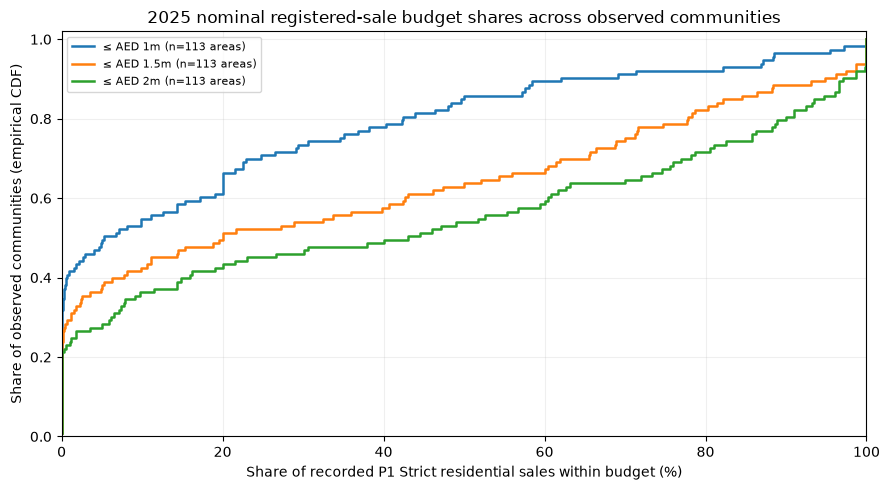

Budget eligibility denominator: community-year P1 Strict registered residential transactions.


In [27]:
# Fixed NOMINAL registered-sale budgets. No listings, wages, or financing assumptions.
BUDGETS=[1000000,1500000,2000000]
budget_rows=[]
for (area,yr),d in r.groupby(['area_key','year'],observed=True):
    for budget in BUDGETS:
        within=d.loc[d.price_aed.le(budget)]
        budget_rows.append(dict(area_key=area,year=int(yr),budget_aed=budget,
            denominator_n=len(d),within_budget_n=len(within),
            within_budget_pct=100*len(within)/len(d),
            median_area_sqm=within.area_sqm.median(),
            known_bedroom_n=int(within.known_rooms.sum()),
            known_bedroom_pct=100*within.known_rooms.mean() if len(within) else np.nan))
community_budget_accessibility=pd.DataFrame(budget_rows)
assert community_budget_accessibility.within_budget_n.le(community_budget_accessibility.denominator_n).all()
for _,d in community_budget_accessibility.groupby(['area_key','year'],observed=True):
    assert np.diff(d.sort_values('budget_aed').within_budget_n.to_numpy()).min()>=0
# Use three threshold-specific empirical cumulative distributions rather than
# overlapping histograms. Include every community with 2025 P1 Strict sales.
fig,ax=plt.subplots(figsize=(9,5))
view=community_budget_accessibility.loc[community_budget_accessibility.year.eq(T1)]
for b,d in view.groupby('budget_aed',observed=True):
    vals=np.sort(d.within_budget_pct.to_numpy(dtype=float))
    if len(vals):ax.step(vals,np.arange(1,len(vals)+1)/len(vals),where='post',
                         linewidth=1.8,label=f'≤ AED {b/1e6:g}m (n={len(vals)} areas)')
ax.set(xlim=(0,100),ylim=(0,1.02),xlabel='Share of recorded P1 Strict residential sales within budget (%)',
       ylabel='Share of observed communities (empirical CDF)',
       title=f'{T1} nominal registered-sale budget shares across observed communities')
ax.legend(fontsize=8);ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(FIG/'04_community_budget.png',dpi=155,bbox_inches='tight');plt.show()
print('Budget eligibility denominator: community-year P1 Strict registered residential transactions.')


In [28]:
community_budget_property_mix=(r.assign(budget_band=pd.cut(r.price_aed,[-np.inf,1000000,1500000,2000000,np.inf],labels=['<=1m','1–1.5m','1.5–2m','>2m'])).groupby(['area_key','year','budget_band','ptype','reg'],observed=True).agg(n=('transaction_id','size'),median_area=('area_sqm','median'),known_bedroom_n=('known_rooms','sum')).reset_index())
community_budget_property_mix['known_bedroom_pct']=np.where(community_budget_property_mix.n>0,100*community_budget_property_mix.known_bedroom_n/community_budget_property_mix.n,np.nan)
assert community_budget_property_mix.n.sum()==len(r)
display(community_budget_property_mix.loc[community_budget_property_mix.year.eq(T1)].groupby('budget_band',observed=True).n.sum())

budget_band
<=1m      52439
1–1.5m    44791
1.5–2m    23100
>2m       58632
Name: n, dtype: int64

In [29]:
endbudget=community_budget_accessibility.loc[community_budget_accessibility.year.isin([T0,T1])].pivot_table(index=['area_key','budget_aed'],columns='year',values=['within_budget_pct','within_budget_n','denominator_n'])
change=endbudget.reset_index()
for field in ['within_budget_pct','within_budget_n','denominator_n']:
    for yr in (T0,T1):
        if (field,yr) not in change.columns:change[(field,yr)]=np.nan
change['delta_budget_share_pp']=change[('within_budget_pct',T1)]-change[('within_budget_pct',T0)]
# Flatten MultiIndex with stable typed column labels for export/readback.
change.columns=[('_'.join(map(str,c)).strip('_') if isinstance(c,tuple) else str(c)) for c in change.columns]
community_budget_change=change
print('Budget threshold comparisons with both endpoint support:',int(community_budget_change.delta_budget_share_pp.notna().sum()))

Budget threshold comparisons with both endpoint support: 285


In [30]:
community_budget_decisions=community_budget_change[['area_key','budget_aed','delta_budget_share_pp']].copy()
community_budget_decisions['decision']=np.where(community_budget_decisions.delta_budget_share_pp.notna(),'QUALIFIED','NOT ESTIMABLE')
community_budget_decisions['restriction']='Fixed nominal recorded-sales shares only; transaction-property composition and household income unavailable'
assert community_budget_decisions.decision.isin(['QUALIFIED','NOT ESTIMABLE']).all()

## 40 — RQ09: Transparent activity/price profiles rather than investment recommendations
The 2021–2025 activity/price quadrants use P1 Strict residential *transaction counts* for activity and independently supported matched-group estimates for price changes. They are not market liquidity (no housing stock/listing denominator) or risk/return recommendations. A point near zero is not assigned a strong label unless its conditional interval supports a sign; otherwise `UNCERTAIN`. Structural labels retain continuous inputs and use explicit endpoints, rather than opaque clustering.

In [31]:
# Preliminary activity-price profile; final labels and publication plot are
# generated AFTER conditional bootstrap in Cell 46.
res_counts=endpoint_parent.copy()
community_activity_price_regimes=community_growth_validated[
    ['area_key','area_name','selected_design','change_pct','decision']].copy()
community_activity_price_regimes['strict_count_change']=(
    community_activity_price_regimes.area_key.map(res_counts[T1]-res_counts[T0]))
community_activity_price_regimes['regime']=np.select([
    community_activity_price_regimes.change_pct.isna(),
    community_activity_price_regimes.change_pct.gt(0)&community_activity_price_regimes.strict_count_change.gt(0),
    community_activity_price_regimes.change_pct.gt(0)&community_activity_price_regimes.strict_count_change.lt(0),
    community_activity_price_regimes.change_pct.lt(0)&community_activity_price_regimes.strict_count_change.gt(0),
    community_activity_price_regimes.change_pct.lt(0)&community_activity_price_regimes.strict_count_change.lt(0)],
    ['NOT ESTIMABLE','count up / matched price up','count down / matched price up',
     'count up / matched price down','count down / matched price down'],default='ZERO OR AMBIGUOUS')
print('Pre-bootstrap provisional quadrants:',
      community_activity_price_regimes.regime.value_counts().to_dict(),
      '| authoritative plot and labels follow conditional bootstrap in Cell 46.')


Pre-bootstrap provisional quadrants: {'NOT ESTIMABLE': 169, 'count up / matched price up': 31, 'count down / matched price up': 3} | authoritative plot and labels follow conditional bootstrap in Cell 46.


In [32]:
# Interpretable structural composition, not unsupervised clusters.
endpointmix=known.loc[known.year.eq(T1)].groupby('area_key').agg(n=('transaction_id','size'),unit_share=('ptype',lambda s:float(s.eq('Unit').mean())),offplan_share=('reg',lambda s:float(s.eq('Off-Plan').mean()))).reset_index()
community_structural_profiles=community_evidence_registry[['area_key','area_name','active_years']].merge(endpointmix,on='area_key',how='left')
community_structural_profiles['property_profile']=np.select([community_structural_profiles.unit_share.ge(.70),community_structural_profiles.unit_share.le(.30)],['unit-dominant registrations','non-unit-dominant registrations'],default='mixed registrations')
community_structural_profiles['registration_profile']=np.select([community_structural_profiles.offplan_share.ge(.70),community_structural_profiles.offplan_share.le(.30)],['offplan-dominant registrations','ready-or-other-dominant registrations'],default='mixed registration')
community_structural_profiles.loc[community_structural_profiles.n.isna(),'property_profile']='NO 2025 TRANSACTIONS'
community_structural_profiles.loc[community_structural_profiles.n.isna(),'registration_profile']='NO 2025 TRANSACTIONS'

In [33]:
# Changes in structural labels are descriptive, not physical housing-stock transitions.
profile_rows=[]
for yr in [T0,T1]:
    d=known.loc[known.year.eq(yr)].groupby('area_key').agg(n=('transaction_id','size'),unit_share=('ptype',lambda s:float(s.eq('Unit').mean())),offplan_share=('reg',lambda s:float(s.eq('Off-Plan').mean()))).reset_index()
    d['year']=yr;profile_rows.append(d)
community_regime_sensitivity=pd.concat(profile_rows,ignore_index=True)
community_regime_sensitivity['mostly_units']=community_regime_sensitivity.unit_share.ge(.70)
community_regime_sensitivity['mostly_offplan']=community_regime_sensitivity.offplan_share.ge(.70)
print('Community reference-period structural evidence available:',community_regime_sensitivity.area_key.nunique())

Community reference-period structural evidence available: 177


In [34]:
# One row per P0-known community. Missing prices are not replaced by zeros.
community_intelligence_matrix=(community_evidence_registry[['area_key','area_name','p0_n','first_year','last_year','active_years','p1_2021_n','p1_2025_n','p2_retention_2021_pct','p2_retention_2025_pct']].merge(community_growth_validated[['area_key','selected_design','matched_price_eligible','change_pct','coverage_2021_pct','coverage_2025_pct','matched_groups','decision']],on='area_key',how='left',validate='one_to_one').merge(community_structural_profiles[['area_key','unit_share','offplan_share','property_profile','registration_profile']],on='area_key',how='left',validate='one_to_one').merge(community_activity_history[['area_key','change_n']],on='area_key',how='left',validate='one_to_one'))
assert len(community_intelligence_matrix)==len(areas) and community_intelligence_matrix.area_key.is_unique
assert community_intelligence_matrix.loc[~community_intelligence_matrix.matched_price_eligible,'change_pct'].isna().all()
display(community_intelligence_matrix[['area_key','area_name','p0_n','p1_2021_n','p1_2025_n','selected_design','change_pct','decision']].head(12))

,area_key,area_name,p0_n,p1_2021_n,p1_2025_n,selected_design,change_pct,decision
0,230.0,Abu Hail,464,10,25,NONE,NaN,NOT ESTIMABLE
1,231.0,Al Mamzer,342,4,6,NONE,NaN,NOT ESTIMABLE
2,232.0,Mirdif,3509,163,261,A_broad,13.203137,QUALIFIED
3,233.0,Hor Al Anz,1132,18,35,NONE,NaN,NOT ESTIMABLE
4,234.0,Hor Al Anz East,90,3,3,NONE,NaN,NOT ESTIMABLE
5,235.0,Eyal Nasser,111,0,0,NONE,NaN,NOT ESTIMABLE
6,237.0,Al Sabkha,21,0,0,NONE,NaN,NOT ESTIMABLE
7,238.0,Al Dhagaya,150,0,0,NONE,NaN,NOT ESTIMABLE
8,239.0,Al Baraha,128,0,0,NONE,NaN,NOT ESTIMABLE
9,240.0,Port Saeed,594,1,0,NONE,NaN,NOT ESTIMABLE


## 45 — Conditional uncertainty, multiplicity and selection
The primary purpose of resampling is to show **conditional transaction-level variation** given the selected matching groups and 2021 weights. Repeated community comparisons would additionally require defensible common populations, error dependencies and multiple-testing control; these conditions are not established for a universal pairwise ranking, so no significance leaderboard or fabricated FDR-adjusted p-values will be generated. Community bootstrap is restricted to preselected adequately supported endpoints. Sensitivity checks cover matching detail, group-count thresholds and publisher flag policy. Even a very narrow interval does **not** recover missing buildings, unmatched homes, or unobserved quality.

**Revision:** Endpoint percentile bootstraps use 600 replicates and fix the selected segment universe and 2021 weights. Bootstrap intervals remain conditional and are not simultaneous confidence intervals for community rankings. Community-specific P1 Core/Strict comparisons now use their own legitimate parent denominators.


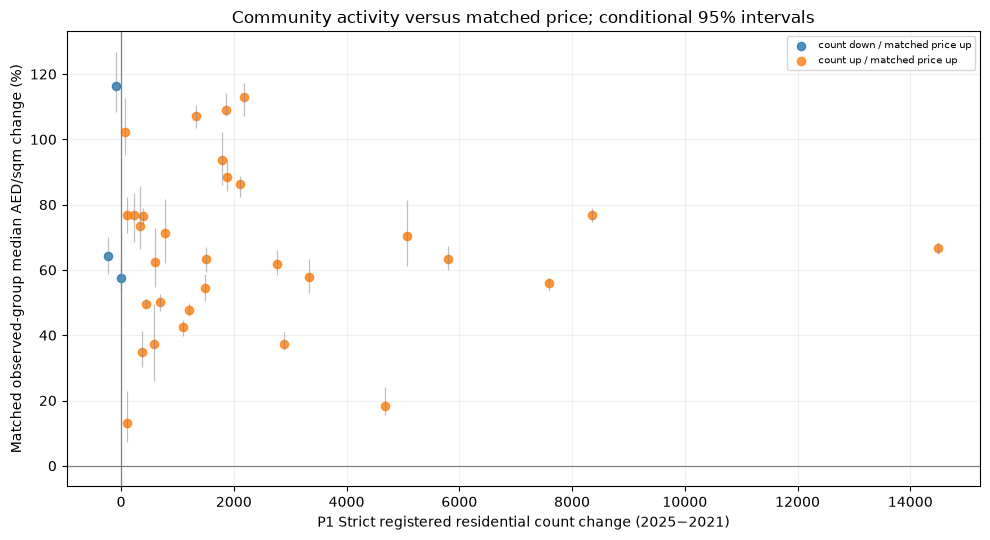

Bootstrap intervals: 34 | replicates per eligible community: 600 | uncertain conditional price signs: 0


In [35]:
# Transaction-within-group/year percentile bootstrap; fixed matched support and
# baseline group weights. The intervals are CONDITIONAL, not stock-wide inference.
BOOT_REPS=600
rng=np.random.default_rng(SEED)
bootrows=[]
for rec in community_matching_decisions.loc[
        community_matching_decisions.matched_price_eligible].itertuples(index=False):
    area,design=rec.area_key,rec.selected_design
    keys=DESIGNS[design]
    part=design_eligible(END.loc[END.area_key.eq(area)],design)
    groups={}
    for group_year,subpart in part.groupby(keys+['year'],observed=True,dropna=False):
        k=tuple(group_year[:-1]);year=int(group_year[-1])
        groups[(k,year)]=subpart.price_per_sqm.to_numpy(dtype=float)
    common=sorted([k for k,yr in groups if yr==T0 and len(groups[(k,T0)])>=30
                   and len(groups.get((k,T1),[]))>=30],key=str)
    assert len(common)>=2,f'Eligible community lost bootstrap support: {area}, {design}'
    sizes=np.array([len(groups[(k,T0)]) for k in common],dtype=float)
    weights=sizes/sizes.sum();assert np.isclose(weights.sum(),1)
    logs=np.zeros(BOOT_REPS,dtype=float)
    for k,w in zip(common,weights):
        v0=groups[(k,T0)];v1=groups[(k,T1)]
        # Bounded memory: one supported group at a time, 600 bootstrap medians.
        med0=np.empty(BOOT_REPS);med1=np.empty(BOOT_REPS)
        for b in range(BOOT_REPS):
            med0[b]=np.median(rng.choice(v0,size=len(v0),replace=True))
            med1[b]=np.median(rng.choice(v1,size=len(v1),replace=True))
        logs+=w*np.log(med1/med0)
    bootrows.append(dict(area_key=area,design=design,replicates=BOOT_REPS,
        ci_low_pct=float(100*np.expm1(np.quantile(logs,.025))),
        ci_high_pct=float(100*np.expm1(np.quantile(logs,.975))),
        conditional_only=True))
community_price_uncertainty=pd.DataFrame(bootrows) if bootrows else pd.DataFrame(
    columns=['area_key','design','replicates','ci_low_pct','ci_high_pct','conditional_only'])
assert community_price_uncertainty.area_key.is_unique
assert set(community_price_uncertainty.area_key)==set(
    community_matching_decisions.loc[community_matching_decisions.matched_price_eligible,'area_key'])
community_activity_price_regimes=community_activity_price_regimes.merge(
    community_price_uncertainty[['area_key','ci_low_pct','ci_high_pct']],
    on='area_key',how='left',validate='one_to_one')
uncertain=(community_activity_price_regimes.change_pct.notna()&(
    community_activity_price_regimes.ci_low_pct.isna()|
    community_activity_price_regimes.ci_high_pct.isna()|
    ((community_activity_price_regimes.ci_low_pct<=0)&(community_activity_price_regimes.ci_high_pct>=0))))
community_activity_price_regimes.loc[uncertain,'regime']='UNCERTAIN CONDITIONAL PRICE SIGN'
# Zero count change also cannot receive a positive/negative activity direction.
assert community_activity_price_regimes.loc[
    community_activity_price_regimes.change_pct.isna(),'regime'].eq('NOT ESTIMABLE').all()

# FINAL visualization: only supported communities; vertical conditional confidence bars.
fig,ax=plt.subplots(figsize=(10,5.5))
d=community_activity_price_regimes.dropna(subset=['change_pct']).copy()
for label,part in d.groupby('regime',observed=True):
    errors=np.vstack([part.change_pct-part.ci_low_pct,
                       part.ci_high_pct-part.change_pct])
    # Percentile interval need not contain plug-in point estimate; draw CI only
    # for finite nonnegative distances, otherwise draw endpoint line segments.
    for rec2 in part.itertuples(index=False):
        ax.vlines(rec2.strict_count_change,rec2.ci_low_pct,rec2.ci_high_pct,
                  color='gray',alpha=.5,lw=.9)
    ax.scatter(part.strict_count_change,part.change_pct,s=35,alpha=.8,label=label)
ax.axhline(0,color='gray',lw=.9);ax.axvline(0,color='gray',lw=.9)
ax.set(xlabel=f'P1 Strict registered residential count change ({T1}−{T0})',
       ylabel='Matched observed-group median AED/sqm change (%)',
       title='Community activity versus matched price; conditional 95% intervals')
ax.legend(fontsize=7,loc='best');ax.grid(alpha=.18);fig.tight_layout()
fig.savefig(FIG/'04_activity_price_regimes.png',dpi=155,bbox_inches='tight');plt.show()

budget2025=community_budget_accessibility.loc[
    community_budget_accessibility.year.eq(T1)].pivot(
    index='area_key',columns='budget_aed',values='within_budget_pct').rename(columns={
    1000000:'budget_1m_pct_2025',1500000:'budget_1_5m_pct_2025',
    2000000:'budget_2m_pct_2025'}).reset_index()
community_intelligence_matrix=(community_intelligence_matrix.merge(
    community_activity_price_regimes[['area_key','regime','ci_low_pct','ci_high_pct']],
    on='area_key',how='left',validate='one_to_one').merge(
    budget2025,on='area_key',how='left',validate='one_to_one'))
# Use the same one-row-per-community stability decision as the published register.
community_intelligence_matrix=community_intelligence_matrix.merge(
    community_stability_decisions[['area_key','sd_log_link']].rename(
    columns={'sd_log_link':'historical_matched_log_volatility'}),
    on='area_key',how='left',validate='one_to_one')
assert community_intelligence_matrix.area_key.is_unique and len(community_intelligence_matrix)==len(areas)
print('Bootstrap intervals:',len(community_price_uncertainty),
      '| replicates per eligible community:',BOOT_REPS,
      '| uncertain conditional price signs:',int(uncertain.sum()))


In [36]:
# Prespecified support/stratum sensitivity PLUS an independently computed
# COMMUNITY-SPECIFIC P1 Core versus P1 Strict sensitivity for selected designs.
sensitivity=[]
for design in DESIGNS:
    for min_n in THRESHOLDS:
        estimates,_=matched_pair(STATS[design],design,T0,T1,min_n)
        if estimates.empty:continue
        feas=community_matching_feasibility.loc[
            community_matching_feasibility.design.eq(design)&
            community_matching_feasibility.min_cell_n.eq(min_n)]
        z=estimates.merge(feas[['area_key','coverage_2021_pct','coverage_2025_pct']],
            on='area_key',how='left',validate='one_to_one')
        z['min_cell_n']=min_n
        sensitivity.append(z[['area_key','design','min_cell_n','matched_groups',
                              'change_pct','coverage_2021_pct','coverage_2025_pct']])
community_research_sensitivity=pd.concat(sensitivity,ignore_index=True) if sensitivity else pd.DataFrame(
    columns=['area_key','design','min_cell_n','matched_groups','change_pct',
             'coverage_2021_pct','coverage_2025_pct'])
# Rebuild the identical observable matching group fields in Core; do not borrow
# Strict eligibility as the Core denominator. Core without finite positive PSM
# is NOT eligible for a group-median price calculation.
core=p1core.loc[p1core.known_area & p1core.year.isin([T0,T1])].copy()
core['known_rooms']=pd.to_numeric(core.rooms_bucket,errors='coerce').isin([0,1,2,3,4,5])
core['size_coarse']=pd.Series(pd.NA,index=core.index,dtype='string')
for ptype,bins in COARSE.items():
    ix=core.ptype.eq(ptype)
    core.loc[ix,'size_coarse']=pd.cut(core.loc[ix,'area_sqm'],bins=bins,
        labels=[f'{ptype}:{j:02d}' for j in range(len(bins)-1)],
        right=True,include_lowest=False).astype('string')
quality_rows=[]
for population,frame in [('P1 Strict',END),('P1 Core',core)]:
    for area in areas:
        design=community_matching_decisions.set_index('area_key').loc[area,'selected_design']
        if design=='NONE':continue
        d=frame.loc[frame.area_key.eq(area)].copy()
        parent=d.groupby('year').size()
        price_usable=d.loc[pd.to_numeric(d.price_per_sqm,errors='coerce').gt(0)&
                           np.isfinite(pd.to_numeric(d.price_per_sqm,errors='coerce'))]
        usable=design_eligible(price_usable,design)
        keys=DESIGNS[design]
        stats=(usable.groupby(['area_key']+keys+['year'],observed=True)
               .agg(n=('transaction_id','size'),median_psm=('price_per_sqm','median')).reset_index())
        summary,_=matched_pair(stats,design,T0,T1,30)
        row=summary.iloc[0] if len(summary) else None
        quality_rows.append(dict(area_key=area,population=population,design=design,
            p1_2021_n=int(parent.get(T0,0)),p1_2025_n=int(parent.get(T1,0)),
            price_usable_2021_n=int(usable.year.eq(T0).sum()),
            price_usable_2025_n=int(usable.year.eq(T1).sum()),
            matched_groups=int(row.matched_groups) if row is not None else 0,
            coverage_2021_pct=(100*row.matched_base_n/parent.get(T0) if row is not None and parent.get(T0,0)>0 else np.nan),
            coverage_2025_pct=(100*row.matched_end_n/parent.get(T1) if row is not None and parent.get(T1,0)>0 else np.nan),
            change_pct=float(row.change_pct) if row is not None else np.nan))
community_quality_sensitivity=pd.DataFrame(quality_rows)
assert not community_quality_sensitivity.duplicated(['area_key','population']).any()
if len(community_quality_sensitivity):
    assert community_quality_sensitivity.loc[
        community_quality_sensitivity.population.eq('P1 Strict'),'change_pct'].notna().all()
    qualitywide=community_quality_sensitivity.pivot(index='area_key',columns='population',values='change_pct')
    qualitywide['core_minus_strict_pp']=qualitywide['P1 Core']-qualitywide['P1 Strict']
    print('Community-specific strict/core comparable change pairs:',
          int(qualitywide.core_minus_strict_pp.notna().sum()))
print('Prespecified matching sensitivity estimates:',len(community_research_sensitivity))


Community-specific strict/core comparable change pairs: 34
Prespecified matching sensitivity estimates: 664


In [37]:
# Conditional interval screening does NOT turn unlike community populations into a fair ranking.
community_comparison_decisions=community_growth_validated[['area_key','selected_design','matched_price_eligible','change_pct','decision','restriction']].merge(community_price_uncertainty[['area_key','ci_low_pct','ci_high_pct']],on='area_key',how='left',validate='one_to_one')
community_comparison_decisions['interval_excludes_zero']=community_comparison_decisions.ci_low_pct.gt(0)|community_comparison_decisions.ci_high_pct.lt(0)
community_comparison_decisions['decision']=np.where(community_comparison_decisions.matched_price_eligible,'QUALIFIED','NOT ESTIMABLE')
community_comparison_decisions['restriction']=community_comparison_decisions['restriction']+'; bootstrap conditional on selected support; cross-community price targets differ'
assert community_comparison_decisions.area_key.is_unique and len(community_comparison_decisions)==len(areas)

In [38]:
# ============================================================
# NOTEBOOK 04 — COMPREHENSIVE RESEARCH VALIDATION
# ============================================================
# Purpose:
# - Validate source and analytical populations.
# - Verify community-level reconciliation.
# - Verify matched-price support and coverage.
# - Preserve legitimately undefined coverage as NaN.
# - Prevent unsupported estimates and misleading regimes.
# - Verify historical, budget and bootstrap integrity.
# - Block downstream exports if a critical check fails.
# ============================================================

checks = []


def check(label, condition, detail=""):
    """Record and enforce an independent research check."""

    ok = bool(condition)

    checks.append({
        "check": label,
        "passed": ok,
        "detail": str(detail)
    })

    if not ok:
        raise AssertionError(
            f"04 research check failed: {label}: {detail}"
        )


# ============================================================
# 1. FROZEN SOURCE AND ANALYTICAL POPULATIONS
# ============================================================

check(
    "Frozen source SHA",
    source.sha256 == SHA
)

check(
    "Source validation",
    validation.passed
)

check(
    "Original columns preserved",
    all(
        raw[c].equals(f[c])
        for c in raw.columns
    )
)

check(
    "No 2026",
    (
        p0.year.between(2010, 2025).all()
        and p1.year.between(2010, 2025).all()
    )
)

check(
    "Unique market IDs",
    p0.transaction_id.is_unique
)

check(
    "P1 Strict subset P0",
    set(p1.transaction_id).issubset(
        set(p0.transaction_id)
    )
)

check(
    "P2 Strict subset",
    set(p2.transaction_id).issubset(
        set(p1.transaction_id)
    )
)

check(
    "Residential prices positive",
    p1.price_per_sqm.gt(0).all()
)


# ============================================================
# 2. GEOGRAPHY AND COMMUNITY POPULATIONS
# ============================================================

check(
    "Geography known + unknown",
    (
        int(p0.known_area.sum())
        + int((~p0.known_area).sum())
        == len(p0)
    )
)

check(
    "Community identity uniqueness",
    community_identity_registry.area_key.is_unique
)

check(
    "All areas evidence registry",
    (
        set(community_evidence_registry.area_key)
        == set(areas)
    )
)

check(
    "P0 community counts",
    (
        int(
            community_yearly_profile.p0_transactions.sum()
        )
        == int(p0.known_area.sum())
    )
)

check(
    "P0 community consideration",
    np.isclose(
        community_yearly_profile[
            "registered_value_aed"
        ].sum(),
        known.price_aed.sum(),
        rtol=1e-12
    )
)

check(
    "P1 community counts",
    (
        int(
            community_yearly_profile.p1_strict_n.sum()
        )
        == int(p1.known_area.sum())
    )
)


# ============================================================
# 3. MATCHED-COVERAGE VALIDATION — CORRECTED
# ============================================================
# IMPORTANT:
#
# Matched coverage = 100 * matched_n / parent_n
#
# If parent_n == 0:
#     matched_n must equal 0
#     coverage must be NaN (undefined)
#
# If parent_n > 0:
#     coverage must be finite and between 0 and 100
#     coverage must equal the exact calculated percentage
#
# Missing coverage is NOT automatically a validation failure.
# ============================================================

check(
    "Matching feasibility registry unique",
    not community_matching_feasibility.duplicated(
        subset=[
            "area_key",
            "design",
            "min_cell_n"
        ]
    ).any()
)

check(
    "Matching feasibility retains all communities",
    (
        set(community_matching_feasibility.area_key)
        == set(areas)
    )
)

for year in [T0, T1]:

    parent_col = f"p1_{year}_n"
    matched_col = f"matched_{year}_n"
    coverage_col = f"coverage_{year}_pct"

    parent = pd.to_numeric(
        community_matching_feasibility[parent_col],
        errors="coerce"
    )

    matched = pd.to_numeric(
        community_matching_feasibility[matched_col],
        errors="coerce"
    )

    coverage = pd.to_numeric(
        community_matching_feasibility[coverage_col],
        errors="coerce"
    )

    # 3A. Parent and matched counts must be valid.
    count_integrity = (
        parent.notna().all()
        and matched.notna().all()
        and np.isfinite(
            parent.to_numpy(dtype=float)
        ).all()
        and np.isfinite(
            matched.to_numpy(dtype=float)
        ).all()
        and parent.ge(0).all()
        and matched.ge(0).all()
        and matched.le(parent).all()
        and np.allclose(
            parent.to_numpy(dtype=float),
            np.round(
                parent.to_numpy(dtype=float)
            )
        )
        and np.allclose(
            matched.to_numpy(dtype=float),
            np.round(
                matched.to_numpy(dtype=float)
            )
        )
    )

    check(
        f"Matched counts within P1 Strict — {year}",
        count_integrity,
        (
            "Parent/matched counts must be finite, "
            "nonnegative integers, and matched <= parent."
        )
    )

    positive_parent = parent.gt(0)
    zero_parent = parent.eq(0)

    # 3B. Undefined denominators must remain undefined.
    zero_parent_integrity = (
        matched.loc[zero_parent].eq(0).all()
        and coverage.loc[zero_parent].isna().all()
    )

    check(
        f"Zero-parent coverage undefined — {year}",
        zero_parent_integrity,
        (
            "Zero P1 Strict parent requires zero matched "
            "transactions and NaN coverage."
        )
    )

    # 3C. Defined coverage must be finite and bounded.
    defined_coverage = coverage.loc[positive_parent]

    coverage_bounds_valid = (
        defined_coverage.notna().all()
        and np.isfinite(
            defined_coverage.to_numpy(dtype=float)
        ).all()
        and defined_coverage.between(
            0,
            100.00001
        ).all()
    )

    check(
        f"Matched coverage bounded — {year}",
        coverage_bounds_valid,
        (
            "Positive-parent coverage must be finite "
            "and within 0–100%."
        )
    )

    # 3D. Independently reconstruct the coverage values.
    expected_coverage = (
        100.0
        * matched.loc[
            positive_parent
        ].to_numpy(dtype=float)
        / parent.loc[
            positive_parent
        ].to_numpy(dtype=float)
    )

    observed_coverage = defined_coverage.to_numpy(
        dtype=float
    )

    arithmetic_valid = np.allclose(
        observed_coverage,
        expected_coverage,
        rtol=1e-12,
        atol=1e-10,
        equal_nan=False
    )

    check(
        f"Matched coverage arithmetic — {year}",
        arithmetic_valid,
        (
            "Coverage must equal "
            "100 * matched P1 Strict / parent P1 Strict."
        )
    )


# ============================================================
# 4. MATCHED PRICE SELECTION AND ESTIMATES
# ============================================================

check(
    "Matching selection support-only",
    community_matching_decisions[
        "selected_design"
    ].isin([
        "A_broad",
        "C_size_only",
        "NONE"
    ]).all()
)

check(
    "No fabricated community price",
    community_growth_validated.loc[
        ~community_growth_validated[
            "matched_price_eligible"
        ],
        "change_pct"
    ].isna().all()
)

endpoint_changes = pd.to_numeric(
    community_price_growth_endpoint[
        "change_pct"
    ],
    errors="coerce"
)

check(
    "Support-eligible estimates finite",
    np.isfinite(
        endpoint_changes.to_numpy(dtype=float)
    ).all()
)

check(
    "Weight concentration valid",
    (
        community_price_growth_endpoint[
            "effective_groups"
        ].ge(1 - 1e-10).all()
        and community_price_growth_endpoint[
            "effective_groups"
        ].notna().all()
    )
)

check(
    "Unmatched communities retained",
    (
        len(community_growth_validated)
        == len(areas)
        and community_growth_validated[
            "area_key"
        ].is_unique
        and set(
            community_growth_validated.area_key
        ) == set(areas)
    )
)


# ============================================================
# 5. HISTORICAL PRICE CONTINUITY
# ============================================================

check(
    "Supported historical links nonzero",
    community_price_history_supported.loc[
        community_price_history_supported[
            "eligible_link"
        ],
        "matched_groups"
    ].ge(2).all()
)

check(
    "Historical continuity constraints",
    community_growth_persistence[
        "max_continuous_positive_links"
    ].le(
        community_growth_persistence[
            "supported_links"
        ]
    ).all()
)

check(
    "Fixed submarket identity",
    (
        SELECTED_SUBMARKET is None
        or isinstance(
            SELECTED_SUBMARKET,
            tuple
        )
    )
)


# ============================================================
# 6. RESIDENTIAL PRICE DISTRIBUTIONS
# ============================================================

check(
    "Within-year medians positive",
    community_within_year_price_dispersion[
        "p50_psm"
    ].gt(0).all()
)


# ============================================================
# 7. COMMUNITY BUDGET VALIDATION
# ============================================================

check(
    "Budget numerator within denominator",
    (
        community_budget_accessibility[
            "within_budget_n"
        ].ge(0).all()
        and community_budget_accessibility[
            "denominator_n"
        ].ge(0).all()
        and community_budget_accessibility[
            "within_budget_n"
        ].le(
            community_budget_accessibility[
                "denominator_n"
            ]
        ).all()
    )
)

# Each community-year's cumulative transaction counts
# must be nondecreasing as the nominal budget increases.
budget_monotonic = (
    community_budget_accessibility
    .sort_values(
        ["area_key", "year", "budget_aed"]
    )
    .groupby(
        ["area_key", "year"],
        observed=True
    )["within_budget_n"]
    .apply(
        lambda s: bool(
            np.all(
                np.diff(
                    s.to_numpy(dtype=float)
                ) >= 0
            )
        )
    )
)

check(
    "Budget threshold monotonic",
    budget_monotonic.all()
)

check(
    "Budget property mix P1",
    (
        int(
            community_budget_property_mix[
                "n"
            ].sum()
        )
        == len(r)
    )
)


# ============================================================
# 8. COMMUNITY COMPARISONS AND MATRIX COMPLETENESS
# ============================================================

check(
    "No investment ranking",
    community_comparison_decisions[
        "decision"
    ].isin([
        "QUALIFIED",
        "NOT ESTIMABLE"
    ]).all()
)

check(
    "Matrix complete",
    (
        community_intelligence_matrix[
            "area_key"
        ].is_unique
        and len(
            community_intelligence_matrix
        ) == len(areas)
        and set(
            community_intelligence_matrix.area_key
        ) == set(areas)
    )
)

required_matrix_fields = [
    "budget_1m_pct_2025",
    "budget_1_5m_pct_2025",
    "budget_2m_pct_2025",
    "ci_low_pct",
    "ci_high_pct",
    "regime"
]

check(
    "Matrix includes planned budget and uncertainty fields",
    all(
        field in community_intelligence_matrix.columns
        for field in required_matrix_fields
    )
)


# ============================================================
# 9. ACTIVITY–PRICE REGIME RELIABILITY
# ============================================================

regimes = community_activity_price_regimes.copy()

# A strong directional regime must not be assigned
# when a complete bootstrap interval includes zero.
uncertain_price_sign = (
    regimes["change_pct"].notna()
    & regimes["ci_low_pct"].notna()
    & regimes["ci_high_pct"].notna()
    & regimes["ci_low_pct"].le(0)
    & regimes["ci_high_pct"].ge(0)
)

uncertain_directional_labels = (
    regimes.loc[
        uncertain_price_sign,
        "regime"
    ]
    .fillna("")
    .astype(str)
    .str.contains(
        r"price up|price down",
        case=False,
        regex=True
    )
)

check(
    "No strong regime for uncertain price signs",
    not uncertain_directional_labels.any()
)


# ============================================================
# 10. CONDITIONAL BOOTSTRAP VALIDATION
# ============================================================

if community_price_uncertainty.empty:

    bootstrap_integrity = True

else:

    bootstrap = community_price_uncertainty.copy()

    lower = pd.to_numeric(
        bootstrap["ci_low_pct"],
        errors="coerce"
    )

    upper = pd.to_numeric(
        bootstrap["ci_high_pct"],
        errors="coerce"
    )

    replicates = pd.to_numeric(
        bootstrap["replicates"],
        errors="coerce"
    )

    bootstrap_integrity = (
        lower.notna().all()
        and upper.notna().all()
        and replicates.notna().all()
        and np.isfinite(
            lower.to_numpy(dtype=float)
        ).all()
        and np.isfinite(
            upper.to_numpy(dtype=float)
        ).all()
        and lower.le(upper).all()
        and replicates.ge(100).all()
    )

check(
    "Conditional bootstrap validity",
    bootstrap_integrity
)


# ============================================================
# 11. FINAL VALIDATION REGISTRY
# ============================================================


# ============================================================
# ADDITIONAL RESEARCH ACCEPTANCE: corrected downstream integrity
# ============================================================
check('Complete calendar activity panel',
    len(comm_hist)==16*len(areas) and
    not comm_hist.duplicated(['area_key','year']).any() and
    comm_hist.loc[comm_hist.prior_n.notna(),'year'].sub(
        comm_hist.loc[comm_hist.prior_n.notna(),'prior_year']).eq(1).all())
check('No fake YoY from zero base',
    comm_hist.loc[comm_hist.prior_n.eq(0),'yoy_pct'].isna().all())
check('Full activity count including zero years',
    int(comm_hist.p0_transactions.sum())==len(known))
check('One stability decision per observed community',
    community_stability_decisions.area_key.is_unique and
    len(community_stability_decisions)==len(areas) and
    set(community_stability_decisions.area_key)==set(areas))
check('Stability cannot be fabricated',
    community_stability_decisions.loc[
        community_stability_decisions.decision.eq('NOT ESTIMABLE'),'sd_log_link'].isna().all())
check('Stability run calendar-contiguous',
    (community_price_stability.last_link-community_price_stability.first_link+1==
     community_price_stability.eligible_links).all())
check('Stability history unique by community/design',
    not community_price_stability.duplicated(['area_key','design']).any())
check('Same endpoint community universe for dispersion',
    community_dispersion_yearly.loc[
        community_dispersion_yearly.year.isin([T0,T1]),'eligible_communities'].nunique()<=1)
check('Dispersion support ID count',
    community_dispersion_yearly.loc[
        community_dispersion_yearly.year.isin([T0,T1]),'eligible_communities'].eq(
        len(FIXED_DISPERSION_AREAS)).all())
check('Bootstrap complete for selected estimates',
    set(community_price_uncertainty.area_key)==set(community_price_growth_endpoint.area_key) and
    community_price_uncertainty.area_key.is_unique)
check('Improved bootstrap precision',
    community_price_uncertainty.empty or
    community_price_uncertainty.replicates.ge(500).all())
check('Selected-community strict/core sensitivity',
    community_quality_sensitivity.empty or
    (set(community_quality_sensitivity.area_key)==set(community_price_growth_endpoint.area_key)
     and set(community_quality_sensitivity.population)=={'P1 Strict','P1 Core'}
     and not community_quality_sensitivity.duplicated(['area_key','population']).any()))
check('Historical stability bootstrap completeness',
    len(community_stability_uncertainty)==len(community_price_stability) and
    not community_stability_uncertainty.duplicated(['area_key','design']).any())
check('Historical volatility conditional interval validity',
    community_stability_uncertainty.empty or (
    community_stability_uncertainty.sd_log_link_ci_low.ge(0).all() and
    community_stability_uncertainty.sd_log_link_ci_low.le(
        community_stability_uncertainty.sd_log_link_ci_high).all() and
    community_stability_uncertainty.volatility_boot_reps.ge(200).all()))
check('Current budget threshold sums reconcile',
    all(int(community_budget_accessibility.loc[
        community_budget_accessibility.year.eq(T1)&
        community_budget_accessibility.budget_aed.eq(b),'within_budget_n'].sum()) ==
        int((r.year.eq(T1)&r.price_aed.le(b)).sum()) for b in BUDGETS))
check('Matrix stability estimate maps to one decision',
    community_intelligence_matrix.area_key.is_unique and
    community_intelligence_matrix.historical_matched_log_volatility.notna().sum()==
    community_stability_decisions.sd_log_link.notna().sum())

community_research_validation = pd.DataFrame(
    checks
)

check_count = len(
    community_research_validation
)

passed_count = int(
    community_research_validation[
        "passed"
    ].sum()
)

# Every validation check must have a unique identifier.
assert community_research_validation[
    "check"
].is_unique, (
    "Duplicate research-validation check labels detected."
)

assert community_research_validation[
    "passed"
].all(), (
    "One or more research validation checks failed."
)

display(
    community_research_validation
)

print("=" * 70)
print("NOTEBOOK 04 — COMPREHENSIVE RESEARCH VALIDATION")
print("=" * 70)

print(
    "Research audit:",
    passed_count,
    "/",
    check_count
)

print(
    "Observed communities:",
    len(areas)
)

print(
    "Community evidence registry:",
    len(community_evidence_registry)
)

print(
    "Community matching feasibility rows:",
    len(community_matching_feasibility)
)

print(
    "Estimated community price changes:",
    len(community_price_growth_endpoint)
)

print(
    "Communities retained in intelligence matrix:",
    len(community_intelligence_matrix)
)

print(
    "Source SHA-256:",
    SHA
)

print("=" * 70)
print("ALL REGISTERED RESEARCH VALIDATION CHECKS PASSED")
print("=" * 70)


,check,passed,detail
0,Frozen source SHA,True,
1,Source validation,True,
2,Original columns preserved,True,
3,No 2026,True,
4,Unique market IDs,True,
5,P1 Strict subset P0,True,
6,P2 Strict subset,True,
7,Residential prices positive,True,
8,Geography known + unknown,True,
9,Community identity uniqueness,True,


NOTEBOOK 04 — COMPREHENSIVE RESEARCH VALIDATION
Research audit: 57 / 57
Observed communities: 203
Community evidence registry: 203
Community matching feasibility rows: 3045
Estimated community price changes: 34
Communities retained in intelligence matrix: 203
Source SHA-256: 8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e
ALL REGISTERED RESEARCH VALIDATION CHECKS PASSED


In [39]:
# Export validated NONEMPTY tables; normalize column names on copies only.
assert community_research_validation.passed.all()
outputs={
'04_source_manifest':source_manifest,'04_cohort_reconciliation':cohort_reconciliation,
'04_identity_registry':community_identity_registry,'04_identity_exceptions':community_identity_exceptions,
'04_cohort_coverage':community_cohort_coverage,'04_ready_villa_selection':ready_villa_selection,'04_continuity':community_continuity,
'04_evidence_registry':community_evidence_registry,'04_yearly_profile':community_yearly_profile,
'04_transaction_mix':community_transaction_mix,'04_mix_change':community_transaction_mix_change,
'04_activity_year_panel':community_activity_year_panel,'04_activity_history':community_activity_history,'04_raw_price_size_history':community_raw_price_size_history,
'04_project_metadata_quality':community_project_metadata_quality,'04_project_label_concentration':community_project_label_concentration,
'04_matching_definitions':community_matching_definitions,'04_matching_feasibility':community_matching_feasibility,
'04_matching_decisions':community_matching_decisions,'04_price_growth_candidates':community_price_growth_candidates,
'04_price_growth_endpoint':community_price_growth_endpoint,'04_price_history_supported':community_price_history_supported,
'04_price_history_coverage':community_price_history_coverage,'04_growth_persistence':community_growth_persistence,
'04_growth_validated':community_growth_validated,'04_growth_ineligible':community_growth_ineligible,
'04_cross_area_overlap':community_cross_area_overlap,'04_price_level_comparisons':community_price_level_comparisons,
'04_dispersion_yearly':community_dispersion_yearly,'04_dispersion_changing_universe':community_dispersion_changing_universe,'04_dispersion_sensitivity':community_dispersion_sensitivity,
'04_convergence_decisions':community_convergence_decisions,'04_within_year_spread':community_within_year_price_dispersion,
'04_price_stability':community_price_stability,'04_stability_reliability':community_price_stability_reliability,'04_stability_uncertainty':community_stability_uncertainty,
'04_stability_decisions':community_stability_decisions,'04_budget_accessibility':community_budget_accessibility,
'04_budget_property_mix':community_budget_property_mix,'04_budget_change':community_budget_change,
'04_budget_decisions':community_budget_decisions,'04_activity_price_regimes':community_activity_price_regimes,
'04_structural_profiles':community_structural_profiles,'04_regime_sensitivity':community_regime_sensitivity,
'04_intelligence_matrix':community_intelligence_matrix,'04_price_uncertainty':community_price_uncertainty,
'04_research_sensitivity':community_research_sensitivity,'04_quality_sensitivity':community_quality_sensitivity,
'04_comparison_decisions':community_comparison_decisions,'04_research_validation':community_research_validation}
export_rows=[];skipped=[]
for name,df in outputs.items():
    if df is None or not isinstance(df,pd.DataFrame) or df.empty:
        skipped.append(name);continue
    out=df.copy();out.columns=[str(c) for c in out.columns]
    assert out.columns.is_unique,f'Duplicate export column labels: {name}'
    csv=OUT/(name+'.csv');pq=AGG/(name+'.parquet')
    out.to_csv(csv,index=False);out.to_parquet(pq,index=False,engine='pyarrow')
    c=pd.read_csv(csv);v=pd.read_parquet(pq,engine='pyarrow')
    assert len(out)==len(c)==len(v) and list(out.columns)==list(c.columns)==list(v.columns)
    for field in out.select_dtypes(include='number').columns:
        a=pd.to_numeric(out[field],errors='coerce').to_numpy(dtype=float)
        b=pd.to_numeric(v[field],errors='coerce').to_numpy(dtype=float)
        assert np.allclose(a,b,equal_nan=True,rtol=1e-10,atol=1e-7),f'Export mismatch {name}.{field}'
    export_rows.append(dict(name=name,rows=len(out),columns=len(out.columns),csv_bytes=csv.stat().st_size,parquet_bytes=pq.stat().st_size,source_sha256=SHA))
community_export_manifest=pd.DataFrame(export_rows)
assert len(community_export_manifest)>=25
print('Verified CSV/Parquet pairs:',len(community_export_manifest),'unsupported/empty skipped:',len(skipped))
display(community_export_manifest)


Verified CSV/Parquet pairs: 49 unsupported/empty skipped: 1


,name,rows,columns,csv_bytes,parquet_bytes,source_sha256
0,04_source_manifest,1,8,206,5364,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
1,04_cohort_reconciliation,4,5,192,3590,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
2,04_identity_registry,203,8,10585,11482,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
3,04_cohort_coverage,6469,4,147057,20919,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
4,04_ready_villa_selection,4,5,212,3464,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
5,04_continuity,203,8,5818,8401,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
6,04_evidence_registry,203,20,25784,21772,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
7,04_yearly_profile,3248,12,297074,124771,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
8,04_transaction_mix,6110,7,315820,95261,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
9,04_mix_change,514,6,33084,15160,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...


In [40]:
# Visualization evidence register: static figure names and matching source tables.
figure_refs=[('04_community_cohort_selection.png','04_cohort_coverage','cohort selection'),('04_community_continuity.png','04_continuity','historical continuity'),('04_community_transaction_mix.png','04_transaction_mix','registration mix'),('04_community_raw_price.png','04_raw_price_size_history','raw price (composition-sensitive)'),('04_community_matched_support.png','04_matching_feasibility','matching support'),('04_price_change_vs_coverage.png','04_price_growth_endpoint','qualified price comparison'),('04_community_price_histories.png','04_price_history_supported','annual adjacent-year observations'),('04_community_price_dispersion.png','04_dispersion_yearly','fixed observable submarket'),('04_community_price_spread.png','04_within_year_spread','price dispersion'),('04_community_budget.png','04_budget_accessibility','nominal transaction budgets'),('04_activity_price_regimes.png','04_activity_price_regimes','conditional activity/price regimes')]
community_figure_index=pd.DataFrame([dict(filename=file,source_table=table,subject=subject,exists=(FIG/file).is_file(),file_bytes=(FIG/file).stat().st_size if (FIG/file).is_file() else 0) for file,table,subject in figure_refs])
assert community_figure_index.exists.all()
figure_out=OUT/'04_figure_index.csv';community_figure_index.to_csv(figure_out,index=False)
display(community_figure_index)

,filename,source_table,subject,exists,file_bytes
0,04_community_cohort_selection.png,04_cohort_coverage,cohort selection,True,25537
1,04_community_continuity.png,04_continuity,historical continuity,True,68799
2,04_community_transaction_mix.png,04_transaction_mix,registration mix,True,165092
3,04_community_raw_price.png,04_raw_price_size_history,raw price (composition-sensitive),True,108302
4,04_community_matched_support.png,04_matching_feasibility,matching support,True,39191
5,04_price_change_vs_coverage.png,04_price_growth_endpoint,qualified price comparison,True,48975
6,04_community_price_histories.png,04_price_history_supported,annual adjacent-year observations,True,48641
7,04_community_price_dispersion.png,04_dispersion_yearly,fixed observable submarket,True,88172
8,04_community_price_spread.png,04_within_year_spread,price dispersion,True,36273
9,04_community_budget.png,04_budget_accessibility,nominal transaction budgets,True,68036


In [41]:
# Final decisions report coverage first; never hardcode direction or select 'winners'.
assert community_research_validation.passed.all()
counts=community_growth_validated.decision.value_counts()
findings=[
 dict(claim_id='COM01',research_question='Evidence reliability',decision='SUPPORTED',interpretation=f'{len(areas)} observed P0 community IDs; {int(community_matching_decisions.matched_price_eligible.sum())} satisfy the preregistered community-wide 2021/2025 matching gate; {int((~community_matching_decisions.matched_price_eligible).sum())} do not.',restriction='Observed source IDs do not prove stable geographic boundaries, housing-stock size, or missing-property representativeness.'),
 dict(claim_id='COM02',research_question='RQ07 matched growth',decision='QUALIFIED' if len(community_price_growth_endpoint) else 'INCONCLUSIVE',interpretation=(f'{len(community_price_growth_endpoint)} supported community-wide matched endpoint estimates; median among those selected estimates {community_price_growth_endpoint.change_pct.median():+.2f}%.' if len(community_price_growth_endpoint) else 'No community-wide endpoint specification passes preregistered matching coverage.'),restriction='Selected areas and differing matched groups; this median of community estimates is not the median property appreciation of Dubai.'),
 dict(claim_id='COM03',research_question='RQ08 common submarket',decision=community_convergence_decisions.decision.iloc[0],interpretation=f'Observed price-level dispersion uses fixed submarket {SELECTED_SUBMARKET} and {len(FIXED_DISPERSION_AREAS)} identical endpoint-supported communities; estimated 2021–2025 SD change: {community_convergence_decisions.sd_log_medians_change_2021_2025.iloc[0]:+.4f} (log units).' if len(FIXED_DISPERSION_AREAS)>=3 else 'Comparable endpoint dispersion not estimable.',restriction='Fixed observable property-type/registration/size stratum; micro-location/building condition remain uncontrolled.'),
 dict(claim_id='COM04',research_question='RQ13 historical stability',decision='QUALIFIED' if len(community_price_stability) else 'INCONCLUSIVE',interpretation=f'{len(community_price_stability)} community/design histories satisfy the consecutive-link screen, representing {int(community_stability_decisions.sd_log_link.notna().sum())} distinct communities; conditional bootstrap intervals are available but selection/building uncertainty remains unidentified.',restriction='Observed changing group-linked price histories, not investor return volatility; unsupported histories are not imputed.'),
 dict(claim_id='COM05',research_question='RQ03 nominal budgets',decision='QUALIFIED',interpretation=f'Community nominal sale-budget shares calculated for AED 1m, 1.5m and 2m over {community_budget_accessibility.area_key.nunique()} residential area IDs.',restriction='Registered-sale distribution is neither household affordability nor current listing availability.'),
 dict(claim_id='COM06',research_question='RQ09 community regimes',decision='QUALIFIED' if len(community_price_growth_endpoint) else 'INCONCLUSIVE',interpretation=f'{int(community_activity_price_regimes.regime.ne("NOT ESTIMABLE").sum())} communities have conditional activity-price quadrant evidence; all others retain explicit insufficient-evidence status.',restriction='No housing-stock liquidity metric, causal price mechanisms, neighborhood investment ranking or future return inference.')
]
community_research_findings=pd.DataFrame(findings)
assert community_research_findings.claim_id.is_unique and community_research_findings.decision.isin(['SUPPORTED','QUALIFIED','INCONCLUSIVE','NOT ESTIMABLE']).all()
csv=OUT/'04_research_findings.csv';pq=AGG/'04_research_findings.parquet'
community_research_findings.to_csv(csv,index=False);community_research_findings.to_parquet(pq,index=False)
assert len(pd.read_csv(csv))==len(pd.read_parquet(pq))==len(community_research_findings)
display(community_research_findings)
print('Notebook 04 — evidence-based conclusions')
print('Source:',SHA,'P0:',len(p0),'P1 Strict:',len(p1))
print('Validation:',int(community_research_validation.passed.sum()),'/',len(community_research_validation))
print('Verified table export pairs including findings:',len(community_export_manifest)+1)
print('Unresolved: property-unit ID, building quality, community boundaries, selection and missing-bedroom bias; stability bootstrap is conditional only. No investment ranking.')


,claim_id,research_question,decision,interpretation,restriction
0,COM01,Evidence reliability,SUPPORTED,203 observed P0 community IDs; 34 satisfy the ...,Observed source IDs do not prove stable geogra...
1,COM02,RQ07 matched growth,QUALIFIED,34 supported community-wide matched endpoint e...,Selected areas and differing matched groups; t...
2,COM03,RQ08 common submarket,QUALIFIED,Observed price-level dispersion uses fixed sub...,Fixed observable property-type/registration/si...
3,COM04,RQ13 historical stability,QUALIFIED,66 community/design histories satisfy the cons...,Observed changing group-linked price histories...
4,COM05,RQ03 nominal budgets,QUALIFIED,Community nominal sale-budget shares calculate...,Registered-sale distribution is neither househ...
5,COM06,RQ09 community regimes,QUALIFIED,34 communities have conditional activity-price...,"No housing-stock liquidity metric, causal pric..."


Notebook 04 — evidence-based conclusions
Source: 8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e P0: 1134513 P1 Strict: 901642
Validation: 57 / 57
Verified table export pairs including findings: 50
Unresolved: property-unit ID, building quality, community boundaries, selection and missing-bedroom bias; stability bootstrap is conditional only. No investment ranking.
